In [1]:
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow
import numpy as np
import math
import datetime

from scipy import signal
from scipy.optimize import curve_fit
from scipy import stats
from scipy.stats import t as t_dist
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from scipy.spatial import KDTree
import matplotlib.pyplot as plt
import matplotlib.ticker as ptick
import matplotlib.colors as mplcolors
from matplotlib.ticker import FixedLocator
from matplotlib.ticker import AutoMinorLocator
import matplotlib.dates as mdates
from matplotlib.patches import FancyArrowPatch, Rectangle
from matplotlib.patches import Wedge
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

from CSField import CSField
import JupiterMag as jm

jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

Importing Library
done


In [2]:
# ============================================================
# 重みづけ最小二乗フィット（1次関数） y = a*x + b
# ============================================================

def weighted_linear_fit(x, y, w):
    """
    重みづけ最小二乗フィット (1次関数)

    Parameters
    ----------
    x     : array-like  説明変数
    y     : array-like  目的変数
    sigma : array-like  各点の標準偏差（測定誤差）

    Returns
    -------
    a, b        : フィット係数 (y = a*x + b)
    sigma_a, sigma_b : 各係数の標準誤差
    """
    # 重みづけ和
    Sw = np.sum(w)
    Swx = np.sum(w * x)
    Swx2 = np.sum(w * x**2)
    Swy = np.sum(w * y)
    Swxy = np.sum(w * x * y)

    # 行列式
    delta = Sw * Swx2 - Swx**2

    # 解析解
    a = (Sw * Swxy - Swx * Swy) / delta
    b = (Swx2 * Swy - Swx * Swxy) / delta

    # 標準誤差
    sigma_a = np.sqrt(Sw / delta)
    sigma_b = np.sqrt(Swx2 / delta)

    return a, b, sigma_a, sigma_b

In [3]:
def day2hhmm(decimal_day):
    doy = int(decimal_day)
    rest = decimal_day - doy

    hours = int(rest*24)
    minutes = (rest*24-hours)*60

    if round(minutes) >= 60:
        hours += 1
        minutes = 0
    else:
        minutes = round(minutes)
    return hours, minutes


def hhmm2day(hours, minutes, seconds=0):
    fraction_of_day = hours/24 + minutes/(60*24) + seconds/(60*60*24)
    return fraction_of_day


def fmt_hhmm(decimal_day):
    hours, minutes = day2hhmm(decimal_day)
    hh = '{:02}'.format(hours)
    mm = '{:02}'.format(minutes)
    return hh+':'+mm

In [4]:
# Data from Connerney+2020: PJ index
con20_pj_idx = np.array([1, 3, 4, 5, 6,
                        7, 8, 9, 10, 11,
                        12, 13, 14, 15, 16,
                        17, 18, 19, 20, 21,
                        22, 23, 24], dtype=int)

# Data from Connerney+2020: Current constant [nT]
con20_mu_i_tot = np.array([150.1, 137.8, 127.2, 129.1, 130.1,
                           142.3, 140.1, 143.8, 137.0, 141.4,
                           124.2, 148.9, 145.3, 144.8, 149.9,
                           132.1, 133.5, 152.9, 138.5, 138.8,
                           156.1, 141.4, 146.3])

# Data from Connerney+2020: Radial current constant [MA]
con20_mu_i_rho = np.array([35.2, 14.6, 7.7, 11.5, 20.8,
                           20.2, 12.2, 21.1, 20.9, 10.7,
                           26.26, 16.4, 12.0, 19.6, 12.0,
                           13.6, 20.0, 12.8, 16.0, 17.3,
                           9.9, 16.1, 10.3])

In [5]:
# 定数
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492*1E+3  # Jupiter radius [m]
RE = 1560*1E+3   # Europa radius [m]
# Angular velocity of Jupiter System III rotation [rad sec-1]
OMG_J = 2*np.pi/(9.55*3600)
OMG_G = 2*np.pi/(7.2*24*3600)   # Ganymede orbital angular velosity [rad/sec]

Psyn_eu = (11.22)*3600      # Moon's synodic period [sec]
Psyn_ga = (10.53)*3600      # Moon's synodic period [sec]

In [6]:
PJ_list = [1, 3, 4, 5,
           6, 7, 8, 9, 10,
           11, 12, 13, 14, 15,
           16, 17, 18, 19, 20,
           21, 22, 23, 24, 25,
           26, 27, 28, 29, 30,
           31, 32, 33, 34, 35,
           36, 37, 38, 39, 40,
           41, 42, 43, 44, 45,
           46, 47, 48, 49, 50,
           51, 52, 53, 54, 55,
           56, 57, 58, 59, 60,
           61, 62, 63, 64, 65,
           66, 67, 68, 69, 70,
           71, 72, 73, 74, 75,
           76, 77, 78, 79, 80]
dir = 'results/insitu_fit_a0_a1_b4_v2_36rj'
f0 = np.loadtxt(dir+'/result_PJ' +
                str(PJ_list[0]).zfill(2)+'_PJ'+str(PJ_list[-1]).zfill(2)+'.txt')

In [7]:
plot_in = 3.0       # Inner edge [RJ]
plot_out = 40.0     # Outer edge [RJ]

# 全データ

In [8]:
PJ_num = 6

a_fit_result = []
b_fit_result = []
sig_a_fit_result = []
sig_b_fit_result = []
Juno_MLT_result = []
Juno_pj_result = []
in_out_result = []
RMSE_result = []

for i in range(2):
    PJ_num = PJ_list[i]

    dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
    time_arr = np.loadtxt(
        dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
    Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
    By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
    Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
    rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
    ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
    rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
    JunoMLT = np.loadtxt(
        dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

    rx_pc *= 1/71492.0  # [RJ]
    ry_pc *= 1/71492.0  # [RJ]
    rz_pc *= 1/71492.0  # [RJ]

    # 座標
    r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
    cos_phi = rx_pc/r_pc
    sin_phi = ry_pc/r_pc
    cos_theta = rz_pc/r_pc
    sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
    # print('Distance [RJ]:', r_pc[0], r_pc[-1])

    # ===========================================================
    # Internal field
    # ===========================================================
    Bx0_pc = np.zeros(time_arr.size)
    By0_pc = np.zeros(time_arr.size)
    Bz0_pc = np.zeros(time_arr.size)
    for i in range(time_arr.size):
        Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                            ry_pc[i],
                                                            rz_pc[i])  # [nT]
    dBx = Bx_pc - Bx0_pc
    dBy = By_pc - By0_pc
    dBz = Bz_pc - Bz0_pc
    dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
    dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
    dBphi = -dBx*sin_phi + dBy*cos_phi

    # ===========================================================
    # DoE model
    # ===========================================================
    csfield = CSField()

    select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
    # print(f0[select_pj, 1], f0[select_pj, 3])

    dBx2_pc = np.zeros(time_arr.size)
    dBy2_pc = np.zeros(time_arr.size)
    dBz2_pc = np.zeros(time_arr.size)
    for i in range(time_arr.size):
        csfield.config(
            i_phi0=f0[select_pj, 1],
            I_rho0=f0[select_pj, 3],
            a0=1.87067601E-6,
            MLT0=2.7409048,
            a1=25.56805279,
            MLT1=18.83227378,
            b1=4.2518,
            b2=0.0,
            MLTb=-0.2086,
        )
        dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field_v2(rx_pc[i],
                                                                       ry_pc[i],
                                                                       rz_pc[i],
                                                                       JunoMLT[i])  # [T]

    x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
    phi_cs = np.arctan2(y_cs, x_cs)
    rho_cs = np.sqrt(x_cs**2 + y_cs**2)
    dBx2_pc *= 1E+9    # [nT]
    dBy2_pc *= 1E+9    # [nT]
    dBz2_pc *= 1E+9    # [nT]
    dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
        sin_theta*sin_phi + dBz2_pc*cos_theta
    dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
        dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
    dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

    # ===========================================================
    # RMSE（Root Mean Squared Error）
    # ===========================================================
    x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
    phi_cs = np.arctan2(y_cs, x_cs)
    rho_cs = np.sqrt(x_cs**2 + y_cs**2)
    in_30rj = np.where(r_pc < plot_out)[0][0]
    out_30rj = np.where(r_pc < plot_out)[0][-1]
    if PJ_num in [17]:
        in_5rj = np.where(rho_cs < 8.0)[0][0]
        out_5rj = np.where(rho_cs < 8.0)[0][-1]
    else:
        in_5rj = np.where(rho_cs < plot_in)[0][0]
        out_5rj = np.where(rho_cs < plot_in)[0][-1]
    in_num = in_5rj-in_30rj-1
    out_num = out_30rj-out_5rj-1

    # ===========================================================
    # Sys3 (x, y, z) -> CS (rho, phi, z)
    # ===========================================================
    dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
    dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
    dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

    dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
    dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
    dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

    # ===========================================================
    # Total RMSE
    # ===========================================================
    RMS_toroidal_cs_inb = math.sqrt(
        (
            np.sum(
                (dBphi_cs[in_30rj:in_5rj]-dBphi2_cs[in_30rj:in_5rj])**2
            )
        )/(in_num)
    )
    RMS_toroidal_cs_outb = math.sqrt(
        (
            np.sum(
                (dBphi_cs[out_5rj:out_30rj]-dBphi2_cs[out_5rj:out_30rj])**2
            )
        )/(out_num)
    )
    print('RMSE (FASTER) [nT]:', round(RMS_toroidal_cs_inb, 2),
          round(RMS_toroidal_cs_outb, 2))

    # ===========================================================
    # Plot boundary
    # ===========================================================
    if PJ_num in [17]:
        r_ticks_ref = np.arange(8.0, plot_out+1, 1)
    else:
        r_ticks_ref = np.arange(plot_in, plot_out+1, 1)
    r_ticks = np.zeros((r_ticks_ref.size*2, 2))
    for i in range(r_ticks_ref.size):
        r_i = r_ticks_ref[-1]-i
        time_i = time_arr[np.where(r_pc < r_i)[0][0]]
        r_ticks[i, 0] = r_i
        r_ticks[i, 1] = time_i

        time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
        r_ticks[-i-1, 0] = r_i
        r_ticks[-i-1, 1] = time_i

    # ===========================================================
    # Plot
    # ===========================================================
    F = ShareXaxis()
    F.fontsize = 22
    F.fontname = 'Liberation Sans Narrow'

    F.set_figparams(nrows=2, figsize=(6.2, 6.5), dpi='L')
    F.initialize()

    F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
                min=-45.0,
                max=45.0,
                ticks=np.arange(-45, 45+1, 9),
                ticklabels=np.abs(np.arange(-45, 45+1, 9)),
                minor_num=3)
    F.set_yaxis(ax_idx=0,
                label=r'$(1/f_z)\cdot \rho_{\rm cs}\cdot \delta B_{\varphi_{\rm cs}}$ [nT$\cdot R_{\rm J}$]',
                min=-300, max=300,
                ticks=np.linspace(-300, 300, 7),
                ticklabels=np.linspace(-300, 300, 7, dtype=int),
                minor_num=10)
    F.set_yaxis(ax_idx=1,
                label=r'MLT [hour]',
                min=0, max=24,
                ticks=np.arange(0, 24, 4),
                ticklabels=np.arange(0, 24, 4, dtype=int),
                minor_num=4)

    # The plot
    inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
    outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]

    rho_cs_inb = rho_cs[in_30rj:in_5rj]
    z_cs_inb = z_cs[in_30rj:in_5rj]
    dBphi_cs_inb = dBphi_cs[in_30rj:in_5rj]
    dBphi2_cs_inb = dBphi2_cs[in_30rj:in_5rj]
    JunoMLT_inb = JunoMLT[in_30rj:in_5rj]
    rho_cs_outb = rho_cs[out_5rj:out_30rj]
    z_cs_outb = z_cs[out_5rj:out_30rj]
    dBphi_cs_outb = dBphi_cs[out_5rj:out_30rj]
    dBphi2_cs_outb = dBphi2_cs[out_5rj:out_30rj]
    JunoMLT_outb = JunoMLT[out_5rj:out_30rj]

    # INBOUND OBSERVATIONS
    g_rho = 0.5*(1.0+np.tanh((rho_cs_inb-3.3)/1.1))
    f_z = -np.sign(z_cs_inb)*g_rho
    f_z = np.where(np.abs(z_cs_inb) > 2.5, f_z, -g_rho*z_cs_inb/2.5)
    eps = 1e-6
    f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
    y_obs = (1/f_z)*rho_cs_inb*dBphi_cs_inb
    F.ax[0].plot(-rho_cs_inb,
                 y_obs,
                 color='k',
                 linewidth=0.7, label='Observations', zorder=2.0)
    F.ax[0].plot(-rho_cs_inb,
                 (1/f_z)*rho_cs_inb*dBphi2_cs_inb,
                 color=UC.red,
                 linewidth=1.8, label='FASTER', zorder=1.0)

    # INBOUND weighted linear fit
    g_rho = 0.5*(1.0+np.tanh((rho_cs_inb-3.3)/1.1))
    f_z = -np.sign(z_cs_inb)*g_rho
    f_z = np.where(np.abs(z_cs_inb) > 2.5, f_z, -g_rho*z_cs_inb/2.5)
    eps = 1e-6
    f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
    a, b, sigma_a, sigma_b = weighted_linear_fit(
        rho_cs_inb*RJ,
        (1/f_z)*(rho_cs_inb*RJ)*(dBphi_cs_inb*1E-9),
        np.abs(f_z))
    a_fit_result += [a]             # beta [T]
    b_fit_result += [b]             # alpha [T m]
    sig_a_fit_result += [sigma_a]   # beta [T]
    sig_b_fit_result += [sigma_b]   # alpha [T m]
    Juno_MLT_result += [JunoMLT_inb[0]]
    in_out_result += [1]
    Juno_pj_result += [PJ_num]
    RMSE_result += [math.sqrt(
        np.sum((y_obs-(a*rho_cs_inb*RJ+b)*1E+9/RJ)**2)/in_num
    )]
    F.ax[0].plot(-rho_cs_inb,
                 (a*rho_cs_inb*RJ+b)*1E+9/RJ,
                 color=UC.blue,
                 linewidth=1.8, label='Weighted', zorder=1.0)

    # OUTBOUND OBSERVATIONS
    g_rho = 0.5*(1.0+np.tanh((rho_cs_outb-3.3)/1.1))
    f_z = -np.sign(z_cs_outb)*g_rho
    f_z = np.where(np.abs(z_cs_outb) > 2.5, f_z, -g_rho*z_cs_outb/2.5)
    eps = 1e-6
    f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
    y_obs = (1/f_z)*rho_cs_outb*dBphi_cs_outb
    F.ax[0].plot(rho_cs_outb,
                 y_obs,
                 color='k',
                 linewidth=0.7, label='Observations', zorder=2.0)
    F.ax[0].plot(rho_cs_outb,
                 (1/f_z)*rho_cs_outb*dBphi2_cs_outb,
                 color=UC.red,
                 linewidth=1.8, label='FASTER', zorder=1.0)

    # OUTBOUND weighted linear fit
    if rho_cs_outb.size > 4:
        g_rho = 0.5*(1.0+np.tanh((rho_cs_outb-3.3)/1.1))
        f_z = -np.sign(z_cs_outb)*g_rho
        f_z = np.where(np.abs(z_cs_outb) > 2.5, f_z, -g_rho*z_cs_outb/2.5)
        eps = 1e-6
        f_z = np.where(np.abs(f_z) < eps, np.sign(f_z)*eps+eps, f_z)
        a, b, sigma_a, sigma_b = weighted_linear_fit(
            rho_cs_outb*RJ,
            (1/f_z)*(rho_cs_outb*RJ)*(dBphi_cs_outb*1E-9),
            np.abs(f_z))
        a_fit_result += [a]             # beta [T]
        b_fit_result += [b]             # alpha [T m]
        sig_a_fit_result += [sigma_a]   # beta [T]
        sig_b_fit_result += [sigma_b]   # alpha [T m]
        Juno_MLT_result += [JunoMLT_outb[-1]]
        in_out_result += [-1]
        Juno_pj_result += [PJ_num]
        RMSE_result += [math.sqrt(
            np.sum((y_obs-(a*rho_cs_outb*RJ+b)*1E+9/RJ)**2)/out_num
        )]
        F.ax[0].plot(rho_cs_outb,
                     (a*rho_cs_outb*RJ+b)*1E+9/RJ,
                     color=UC.blue,
                     linewidth=1.8, label='Weighted', zorder=1.0)

    # MLT
    F.ax[1].plot(-rho_cs_inb,
                 JunoMLT_inb,
                 color='k',
                 linewidth=0.7, label='Observations', zorder=2.0)
    F.ax[1].plot(rho_cs_outb,
                 JunoMLT_outb,
                 color='k',
                 linewidth=0.7, label='Observations', zorder=2.0)
    # Inner shades
    for j in range(2):
        F.ax[j].axvspan(-5.0, 5.0,
                        fc=UC.lightgray, ec=None, zorder=2.5)

    F.ax[0].text(0.09, 0.97, 'PJ'+str(PJ_num).zfill(2),
                 color='k',
                 fontweight='bold',
                 fontsize=F.fontsize,
                 verticalalignment='top',
                 horizontalalignment='left',
                 transform=F.ax[0].transAxes)
    F.ax[0].text(0.02, 0.02, 'Inbound',
                 color='k',
                 fontsize=F.fontsize,
                 verticalalignment='bottom',
                 horizontalalignment='left',
                 transform=F.ax[0].transAxes)
    F.ax[0].text(0.98, 0.02, 'Outbound',
                 color='k',
                 fontsize=F.fontsize,
                 verticalalignment='bottom',
                 horizontalalignment='right',
                 transform=F.ax[0].transAxes)

    plt.savefig('img/B_cs_2components/PJ'+str(PJ_num).zfill(2)+'.png',
                bbox_inches='tight')

    plt.close()

RMSE (FASTER) [nT]: 4.66 5.07
RMSE (FASTER) [nT]: 2.02 2.15


# Field line trace

In [9]:
jm.Internal.Config(Model='jrm33', Degree=1, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)

In [10]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DUSK)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 17.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_N = np.zeros((x0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=18.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_N[j, 0, k] = x_cs/RJ
            result_arr_N[j, 1, k] = y_cs/RJ
            result_arr_N[j, 2, k] = z_cs/RJ
            # result_arr_N[j, 0, k] = x/RJ
            # result_arr_N[j, 1, k] = y/RJ
            # result_arr_N[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z > 55.0*RJ:
            print('North edge [km]:')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

North edge [km]:
55.057249790467004 -2.131447244850899
North edge [km]:
60.40598637408928 23.274311714583565
North edge [km]:
70.35678317440214 29.612101602074333
Horizontal edge
77.41896835525678 29.105392085659087
Horizontal edge
68.36003847435185 27.884176933024854
Horizontal edge
62.767824489828214 27.136672315365388
Horizontal edge
60.151901542111126 26.351151505517358
Jupiter surface
0.8988768136322517 0.06869568589428167
Jupiter surface
0.8990760538785817 0.07456226993857633
Jupiter surface
0.8996171116669486 0.07899440891892857
Jupiter surface
0.899923181740696 0.08923196690051527
Jupiter surface
0.89942820340713 0.09999850421127612
Jupiter surface
0.8991291766807296 0.11095805791132989
Jupiter surface
0.8998069206086923 0.12213572309466099
Jupiter surface
0.8991211083734975 0.1329216585225507
Jupiter surface
0.899993282751702 0.1439770435869167


In [11]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DUSK)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([-178.0, -176.0, -174.0, -172.0, -170.0, -168.0, -166.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_S = np.zeros((x0.size, 3, int(Niter/10)))

# 南半球から北半球へ
ns = -1     # -1: north; 1: south
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=18.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_S[j, 0, k] = x_cs/RJ
            result_arr_S[j, 1, k] = y_cs/RJ
            result_arr_S[j, 2, k] = z_cs/RJ
            # result_arr_S[j, 0, k] = x/RJ
            # result_arr_S[j, 1, k] = y/RJ
            # result_arr_S[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z < -55.0*RJ:
            print('South edge [km]:')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

South edge [km]:
55.057249790468006 2.1314472448513713
South edge [km]:
60.40598637408992 -23.274311714582637
South edge [km]:
70.35678317439852 -29.612101602075956
Horizontal edge
77.418968355255 -29.105392085660057
Horizontal edge
68.36003847435293 -27.884176933024552
Horizontal edge
62.76782448982735 -27.136672315365637
Horizontal edge
60.151901542111645 -26.35115150551754


In [12]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DAWN)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 17.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)
print(np.sqrt(x_cs0**2+y_cs0**2+z_cs0**2)/RJ)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

print(np.sqrt(x0**2+y0**2+z0**2)/RJ)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_N2 = np.zeros((x0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=6.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_N2[j, 0, k] = x_cs/RJ
            result_arr_N2[j, 1, k] = y_cs/RJ
            result_arr_N2[j, 2, k] = z_cs/RJ
            # result_arr_N[j, 0, k] = x/RJ
            # result_arr_N[j, 1, k] = y/RJ
            # result_arr_N[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z > 55.0*RJ:
            print('North edge [km]:')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002
 1.002 1.002 1.002 1.002]
[1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002 1.002
 1.002 1.002 1.002 1.002]
North edge [km]:
57.62905916852786 7.019649274635215
North edge [km]:
61.10181608585912 17.138721640001414
North edge [km]:
67.86584499589466 28.795554946093336
North edge [km]:
80.41553214161429 47.74127208715749
Horizontal edge
70.22558324844697 43.25676891971314
Horizontal edge
63.5923122561132 40.17709376983568
Horizontal edge
60.36250747589771 39.10531703684381
Jupiter surface
0.8995040268623539 0.06818410967224893
Jupiter surface
0.8995403613691949 0.0750469087154919
Jupiter surface
0.8999660694010869 0.07946380054407388
Jupiter surface
0.8988073050689329 0.08925483099457657
Jupiter surface
0.8988881732046321 0.10005214961744761
Jupiter surface
0.899418703417964 0.11113559755046723
Jupiter surface
0.8998585273302728 0.12222900697213898
Jupiter surface
0.8990359289246486 0.1329555073129

In [13]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DAWN)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([-178.0, -176.0, -174.0, -172.0, -170.0, -168.0, -166.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)
print(np.sqrt(x_cs0**2+y_cs0**2+z_cs0**2)/RJ)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

print(np.sqrt(x0**2+y0**2+z0**2)/RJ)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_S2 = np.zeros((x0.size, 3, int(Niter/10)))

# 南半球から北半球へ
ns = -1     # -1: north; 1: south
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=6.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_S2[j, 0, k] = x_cs/RJ
            result_arr_S2[j, 1, k] = y_cs/RJ
            result_arr_S2[j, 2, k] = z_cs/RJ
            # result_arr_S2[j, 0, k] = x/RJ
            # result_arr_S2[j, 1, k] = y/RJ
            # result_arr_S2[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z < -55.0*RJ:
            print('South edge [km]:')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

[1.002 1.002 1.002 1.002 1.002 1.002 1.002]
[1.002 1.002 1.002 1.002 1.002 1.002 1.002]
South edge [km]:
57.629059168528805 -7.019649274627817
South edge [km]:
61.10181608585832 -17.13872164000347
South edge [km]:
67.86584499589443 -28.795554946096157
South edge [km]:
80.41553214161296 -47.74127208715519
Horizontal edge
70.22558324844617 -43.25676891971261
Horizontal edge
63.59231225611389 -40.17709376983733
Horizontal edge
60.362507475897814 -39.10531703684388


# Selected PJ

In [14]:
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)

In [15]:
PJ_num = 5

dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(
    dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(
    dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]

# 座標
r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
cos_phi = rx_pc/r_pc
sin_phi = ry_pc/r_pc
cos_theta = rz_pc/r_pc
sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
# print('Distance [RJ]:', r_pc[0], r_pc[-1])

# ===========================================================
# Internal field
# ===========================================================
Bx0_pc = np.zeros(time_arr.size)
By0_pc = np.zeros(time_arr.size)
Bz0_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                        ry_pc[i],
                                                        rz_pc[i])  # [nT]
dBx = Bx_pc - Bx0_pc
dBy = By_pc - By0_pc
dBz = Bz_pc - Bz0_pc
dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
dBphi = -dBx*sin_phi + dBy*cos_phi

# ===========================================================
# DoE model
# ===========================================================
csfield = CSField()

select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
# print(f0[select_pj, 1], f0[select_pj, 3])

dBx2_pc = np.zeros(time_arr.size)
dBy2_pc = np.zeros(time_arr.size)
dBz2_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    csfield.config(
        i_phi0=f0[select_pj, 1],
        I_rho0=f0[select_pj, 3],
        a0=1.87067601E-6,
        MLT0=2.7409048,
        a1=25.56805279,
        MLT1=18.83227378,
        b1=4.2518,
        b2=0.0,
        MLTb=-0.2086,
    )
    dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field_v2(rx_pc[i],
                                                                   ry_pc[i],
                                                                   rz_pc[i],
                                                                   JunoMLT[i])  # [T]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
dBx2_pc *= 1E+9    # [nT]
dBy2_pc *= 1E+9    # [nT]
dBz2_pc *= 1E+9    # [nT]
dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
    sin_theta*sin_phi + dBz2_pc*cos_theta
dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
    dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

# ===========================================================
# Inner & Outer Edges
# ===========================================================
x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
in_30rj = np.where(r_pc < plot_out)[0][0]
out_30rj = np.where(r_pc < plot_out)[0][-1]
if PJ_num in [17]:
    in_5rj = np.where(rho_cs < 8.0)[0][0]
    out_5rj = np.where(rho_cs < 8.0)[0][-1]
else:
    in_5rj = np.where(rho_cs < plot_in)[0][0]
    out_5rj = np.where(rho_cs < plot_in)[0][-1]
in_num = in_5rj-in_30rj-1
out_num = out_30rj-out_5rj-1

# ===========================================================
# Sys3 (x, y, z) -> CS (rho, phi, z)
# ===========================================================
dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

# ===========================================================
# Total RMSE
# ===========================================================
RMS_toroidal_cs_inb = math.sqrt(
    (
        np.sum(
            (dBphi_cs[in_30rj:in_5rj]-dBphi2_cs[in_30rj:in_5rj])**2
        )
    )/(in_num)
)
RMS_toroidal_cs_outb = math.sqrt(
    (
        np.sum(
            (dBphi_cs[out_5rj:out_30rj]-dBphi2_cs[out_5rj:out_30rj])**2
        )
    )/(out_num)
)
print('RMSE (FASTER) [nT]:', round(RMS_toroidal_cs_inb, 2),
      round(RMS_toroidal_cs_outb, 2))

# ===========================================================
# Plot boundary
# ===========================================================
if PJ_num in [17]:
    r_ticks_ref = np.arange(8.0, plot_out+1, 1)
else:
    r_ticks_ref = np.arange(plot_in, plot_out+1, 1)
r_ticks = np.zeros((r_ticks_ref.size*2, 2))
for i in range(r_ticks_ref.size):
    r_i = r_ticks_ref[-1]-i
    time_i = time_arr[np.where(r_pc < r_i)[0][0]]
    r_ticks[i, 0] = r_i
    r_ticks[i, 1] = time_i

    time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
    r_ticks[-i-1, 0] = r_i
    r_ticks[-i-1, 1] = time_i

# ===========================================================
# B_phi residuals
# ===========================================================
Bphi_cs_res = dBphi_cs-dBphi2_cs

RMSE (FASTER) [nT]: 1.84 2.46


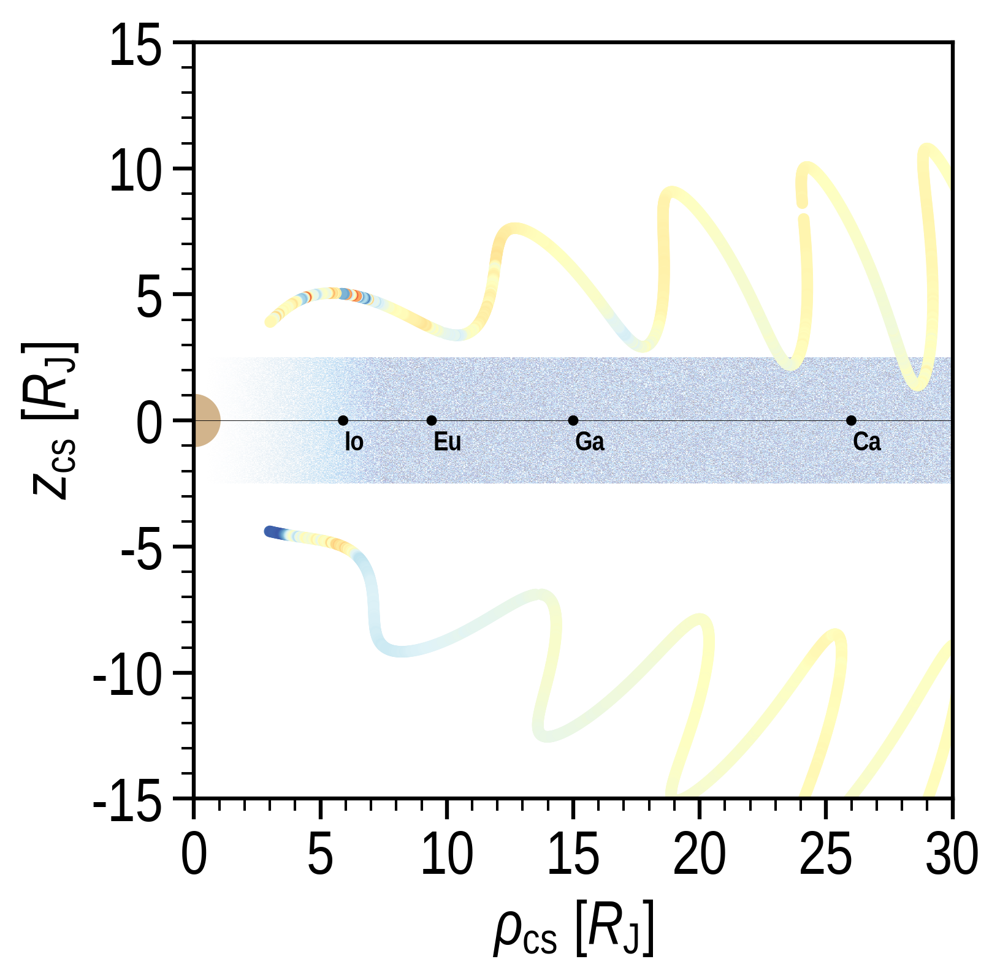

In [16]:
# ===========================================================
# Plot
# ===========================================================
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.2, 5.), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0, max=30.0,
            ticks=np.arange(0, 30+1, 5),
            ticklabels=np.arange(0, 30+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-15.0, max=15.0,
            ticks=np.arange(-15, 15+1, 5),
            ticklabels=np.arange(-15, 15+1, 5, dtype=int),
            minor_num=5,)

cmap = plt.get_cmap('RdYlBu')
F.ax.scatter(rho_cs[in_30rj:in_5rj],
             z_cs[in_30rj:in_5rj],
             c=Bphi_cs_res[in_30rj:in_5rj],
             vmin=-20, vmax=20, cmap=cmap,
             s=10)
F.ax.scatter(rho_cs[out_5rj:out_30rj],
             z_cs[out_5rj:out_30rj],
             c=Bphi_cs_res[out_5rj:out_30rj],
             vmin=-20, vmax=20, cmap=cmap,
             s=10)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
weight = np.clip(np.linspace(0.0, 50.0, noise.shape[1])/7.5, 0.0, 1.0)**2.0
noise *= weight[None, :]
im = F.ax.imshow(
    noise,
    extent=[0.0, 50.0, -2.5, 2.5],
    origin="lower",
    cmap=F.IDL_blue_white(reverse=True),
    alpha=0.28,
    interpolation="nearest",
    aspect="auto",
)

# Jupiter
F.ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                          zorder=2, fill=True, clip_on=True))

# Galilean moons
F.ax.axhline(y=0.0, color='k', linewidth=0.2)
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-0.4, -0.4, -0.4, -0.4]
for i in range(len(radii)):
    F.ax.add_patch(plt.Circle((radii[i], 0), 0.15, color='k',
                              zorder=2, fill=True, clip_on=True))
    F.ax.text(radii[i]+0.05, labelz[i], name[i],
              color='k',
              fontweight='bold',
              fontsize=F.fontsize*0.45,
              verticalalignment='top',
              horizontalalignment='left',)

Text(0.5, 1.0, 'Azimuthal field residuals')

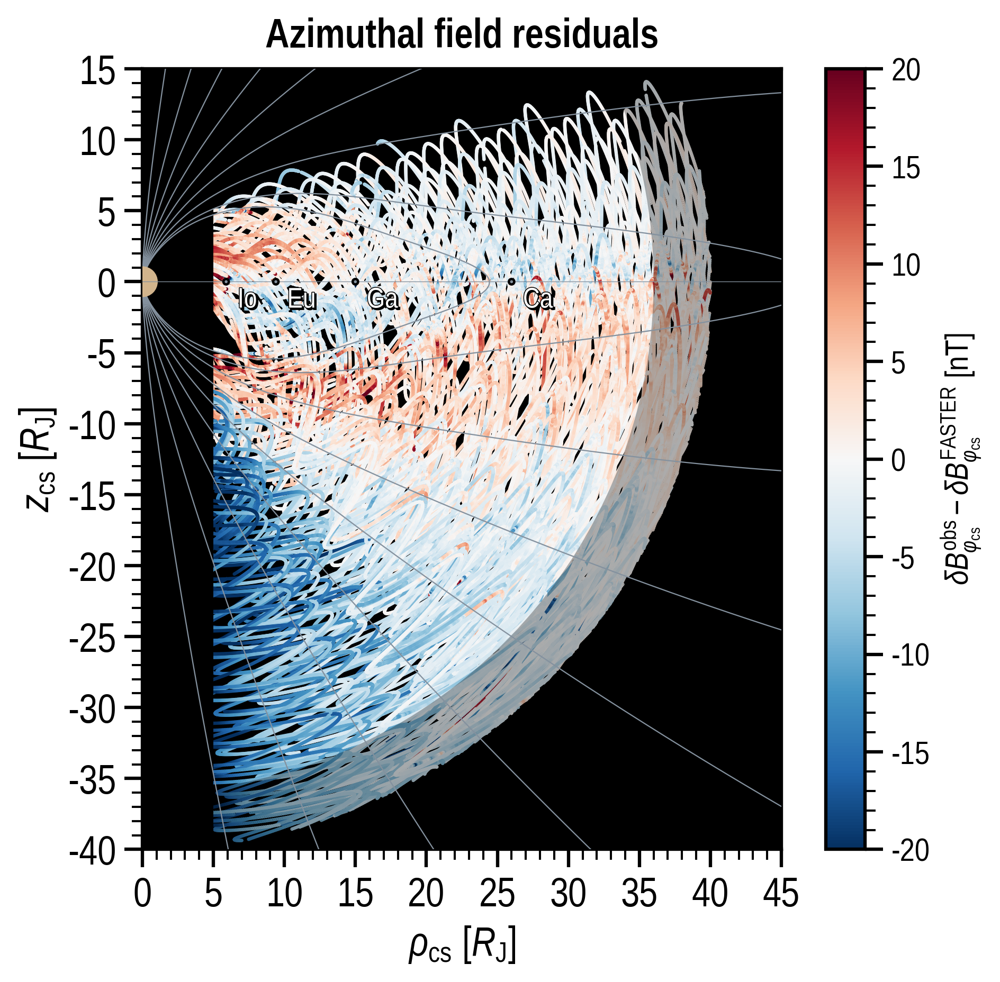

In [17]:
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

# ===========================================================
# Initialize the list
# ===========================================================
Brho_cs_res_5_36 = []
Bphi_cs_res_5_36 = []
Bz_cs_res_5_36 = []
dBrho_cs_5_36 = []
rho_cs_5_36 = []
phi_cs_5_36 = []
z_cs_5_36 = []
JunoMLT_5_36 = []

# ===========================================================
# Plot settings
# ===========================================================
F = ShareXaxis()
F.fontsize = 17
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(6.2, 5.5), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0, max=40.0,
            ticks=np.arange(0, 45+1, 5),
            ticklabels=np.arange(0, 45+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-40.0, max=15.0,
            ticks=np.arange(-40, 15+1, 5),
            ticklabels=np.arange(-40, 15+1, 5, dtype=int),
            minor_num=5,)
F.ax.set_facecolor('k')
cmap = plt.get_cmap('RdBu_r')


# ===========================================================
# Data load and plot the B_phi residuals
# ===========================================================
for i in range(len(PJ_list)):
    PJ_num = PJ_list[i]

    dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
    time_arr = np.loadtxt(
        dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
    Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
    By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
    Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
    rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
    ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
    rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
    JunoMLT = np.loadtxt(
        dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

    rx_pc *= 1/71492.0  # [RJ]
    ry_pc *= 1/71492.0  # [RJ]
    rz_pc *= 1/71492.0  # [RJ]

    # 座標
    r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
    cos_phi = rx_pc/r_pc
    sin_phi = ry_pc/r_pc
    cos_theta = rz_pc/r_pc
    sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
    # print('Distance [RJ]:', r_pc[0], r_pc[-1])

    # ===========================================================
    # Internal field
    # ===========================================================
    Bx0_pc = np.zeros(time_arr.size)
    By0_pc = np.zeros(time_arr.size)
    Bz0_pc = np.zeros(time_arr.size)
    for i in range(time_arr.size):
        Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                            ry_pc[i],
                                                            rz_pc[i])  # [nT]
    dBx = Bx_pc - Bx0_pc
    dBy = By_pc - By0_pc
    dBz = Bz_pc - Bz0_pc
    dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
    dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
    dBphi = -dBx*sin_phi + dBy*cos_phi

    # ===========================================================
    # DoE model
    # ===========================================================
    csfield = CSField()

    select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
    # print(f0[select_pj, 1], f0[select_pj, 3])

    dBx2_pc = np.zeros(time_arr.size)
    dBy2_pc = np.zeros(time_arr.size)
    dBz2_pc = np.zeros(time_arr.size)
    for i in range(time_arr.size):
        csfield.config(
            i_phi0=f0[select_pj, 1],
            I_rho0=f0[select_pj, 3],
            a0=1.87067601E-6,
            MLT0=2.7409048,
            a1=25.56805279,
            MLT1=18.83227378,
            b1=4.2518,
            b2=0.0,
            MLTb=-0.2086,
        )
        dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field_v2(rx_pc[i],
                                                                       ry_pc[i],
                                                                       rz_pc[i],
                                                                       JunoMLT[i])  # [T]

    x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
    phi_cs = np.arctan2(y_cs, x_cs)
    rho_cs = np.sqrt(x_cs**2 + y_cs**2)
    dBx2_pc *= 1E+9    # [nT]
    dBy2_pc *= 1E+9    # [nT]
    dBz2_pc *= 1E+9    # [nT]
    dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
        sin_theta*sin_phi + dBz2_pc*cos_theta
    dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
        dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
    dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

    # ===========================================================
    # Inner & Outer Edges
    # ===========================================================
    x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
    phi_cs = np.arctan2(y_cs, x_cs)
    rho_cs = np.sqrt(x_cs**2 + y_cs**2)
    in_30rj = np.where(r_pc < plot_out)[0][0]
    out_30rj = np.where(r_pc < plot_out)[0][-1]
    if PJ_num in [17]:
        in_5rj = np.where(rho_cs < 8.0)[0][0]
        out_5rj = np.where(rho_cs < 8.0)[0][-1]
    else:
        in_5rj = np.where(rho_cs < plot_in)[0][0]
        out_5rj = np.where(rho_cs < plot_in)[0][-1]
    in_num = in_5rj-in_30rj-1
    out_num = out_30rj-out_5rj-1

    # ===========================================================
    # Sys3 (x, y, z) -> CS (rho, phi, z)
    # ===========================================================
    dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
    dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
    dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

    dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
    dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
    dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

    # ===========================================================
    # B_rho_cs residuals
    # ===========================================================
    Brho_cs_res = dBrho_cs-dBrho2_cs

    # ===========================================================
    # B_phi_cs residuals
    # ===========================================================
    Bphi_cs_res = dBphi_cs-dBphi2_cs

    # ===========================================================
    # B_z_cs residuals
    # ===========================================================
    Bz_cs_res = dBz_cs-dBz2_cs

    # ===========================================================
    # Color coded plot
    # ===========================================================
    F.ax.scatter(rho_cs[in_30rj:in_5rj],
                 z_cs[in_30rj:in_5rj],
                 c=Bphi_cs_res[in_30rj:in_5rj],
                 vmin=-20, vmax=20, cmap=cmap,
                 s=0.2,)
    F.ax.scatter(rho_cs[out_5rj:out_30rj],
                 z_cs[out_5rj:out_30rj],
                 c=Bphi_cs_res[out_5rj:out_30rj],
                 vmin=-20, vmax=20, cmap=cmap,
                 s=0.2,)

    # ===========================================================
    # Save to the list
    # ===========================================================
    Brho_cs_res_5_36 += Brho_cs_res[in_30rj:in_5rj].tolist()
    Bphi_cs_res_5_36 += Bphi_cs_res[in_30rj:in_5rj].tolist()
    Bz_cs_res_5_36 += Bz_cs_res[in_30rj:in_5rj].tolist()
    rho_cs_5_36 += rho_cs[in_30rj:in_5rj].tolist()
    phi_cs_5_36 += phi_cs[in_30rj:in_5rj].tolist()
    z_cs_5_36 += z_cs[in_30rj:in_5rj].tolist()
    JunoMLT_5_36 += JunoMLT[in_30rj:in_5rj].tolist()

    Brho_cs_res_5_36 += Brho_cs_res[out_5rj:out_30rj].tolist()
    Bphi_cs_res_5_36 += Bphi_cs_res[out_5rj:out_30rj].tolist()
    Bz_cs_res_5_36 += Bz_cs_res[out_5rj:out_30rj].tolist()
    rho_cs_5_36 += rho_cs[out_5rj:out_30rj].tolist()
    phi_cs_5_36 += phi_cs[out_5rj:out_30rj].tolist()
    z_cs_5_36 += z_cs[out_5rj:out_30rj].tolist()
    JunoMLT_5_36 += JunoMLT[out_5rj:out_30rj].tolist()

    dBrho_cs_5_36 += dBrho_cs[in_30rj:in_5rj].tolist()
    dBrho_cs_5_36 += dBrho_cs[out_5rj:out_30rj].tolist()

Brho_cs_res_5_36 = np.array(Brho_cs_res_5_36)
Bphi_cs_res_5_36 = np.array(Bphi_cs_res_5_36)
Bz_cs_res_5_36 = np.array(Bz_cs_res_5_36)
rho_cs_5_36 = np.array(rho_cs_5_36)
phi_cs_5_36 = np.array(phi_cs_5_36)
z_cs_5_36 = np.array(z_cs_5_36)
JunoMLT_5_36 = np.array(JunoMLT_5_36)
dBrho_cs_5_36 = np.array(dBrho_cs_5_36)

# ===========================================================
# Dummy
# ===========================================================
sc = F.ax.scatter(-999.9,
                  -999.9,
                  c=0.0,
                  vmin=-20, vmax=20, cmap=cmap,
                  s=0.6,)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]-7):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_N[i, 2, :],
              linewidth=0.5, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_S[i, 2, :],
              linewidth=0.5, color=UC.gray, zorder=5)

# ===========================================================
# Jupiter
# ===========================================================
F.ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                          zorder=6, fill=True, clip_on=True))

# ===========================================================
# Galilean moons
# ===========================================================
F.ax.axhline(y=0.0, color=UC.gray, linewidth=0.3, zorder=7)
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-1.1, -1.1, -1.1, -1.1]
for i in range(len(radii)):
    F.ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                              zorder=8, fill=True, clip_on=True))
    F.textbox(ax_idx=0,
              x=radii[i]+0.8, y=labelz[i],
              text=name[i],
              textedge=True,
              fontsize=F.fontsize*0.7,
              facealpha=0.0,
              edgecolor='none',
              zorder=8)

# ===========================================================
# Hatch mask outside 36 RJ
# ===========================================================
for r_in, r_out in [(36, 41)]:
    # 上半分（z_cs > 0, つまり角度0-180度）
    wedge_top = Wedge(
        center=(0, 0),      # 木星の位置
        r=r_out,            # 外半径
        theta1=0,           # 開始角度
        theta2=360,         # 終了角度
        width=r_out - r_in,  # 幅 = 4 RJ
        facecolor='k',
        edgecolor=None,
        alpha=0.30,
        linewidth=0.5,
        transform=F.ax.transData,
        zorder=4.9,
    )
    F.ax.add_patch(wedge_top)
F.ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)

# ===========================================================
# Colorbar
# ===========================================================
cax = F.fig.colorbar(sc, ax=F.ax)
cax.ax.set_yticks(np.arange(-20, 20+1, 5))
cax.ax.set_yticklabels(np.arange(-20, 20+1, 5, dtype=int),
                       fontsize=F.fontsize*0.8)
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
cax.ax.set_ylabel(
    r'$\delta B_{\varphi_{\rm cs}}^{\rm obs}-\delta B_{\varphi_{\rm cs}}^{\rm FASTER}$ [nT]',
    fontsize=F.fontsize*0.8)

F.ax.set_title('Azimuthal field residuals', weight='bold')

Text(0.5, 1.0, 'Radial field residuals')

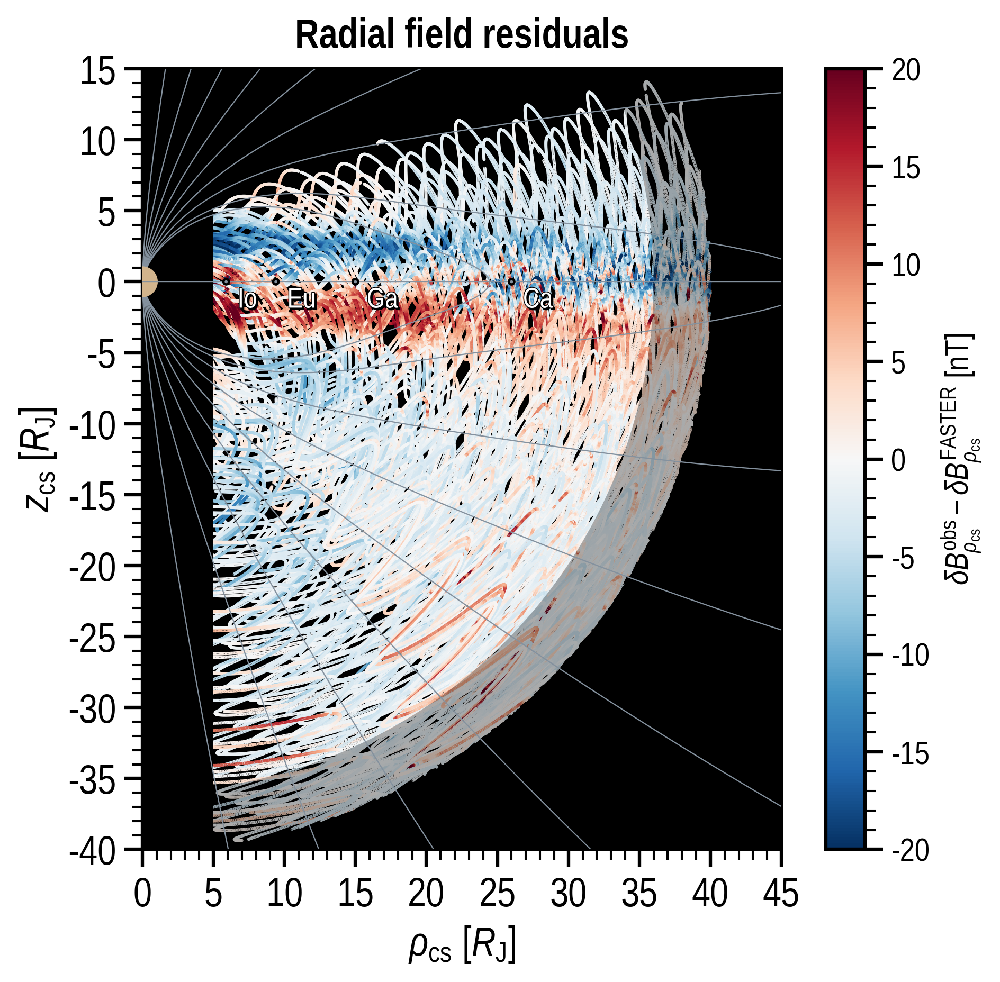

In [18]:
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

# ===========================================================
# Plot settings
# ===========================================================
F = ShareXaxis()
F.fontsize = 17
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(6.2, 5.5), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0, max=40.0,
            ticks=np.arange(0, 45+1, 5),
            ticklabels=np.arange(0, 45+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-40.0, max=15.0,
            ticks=np.arange(-40, 15+1, 5),
            ticklabels=np.arange(-40, 15+1, 5, dtype=int),
            minor_num=5,)
F.ax.set_facecolor('k')
cmap = plt.get_cmap('RdBu_r')

# ===========================================================
# Color coded plot
# ===========================================================
F.ax.scatter(rho_cs_5_36,
             z_cs_5_36,
             c=Brho_cs_res_5_36,
             vmin=-20, vmax=20, cmap=cmap,
             s=0.1,)

# ===========================================================
# Dummy
# ===========================================================
sc = F.ax.scatter(-999.9,
                  -999.9,
                  c=0.0,
                  vmin=-20, vmax=20, cmap=cmap,
                  s=0.6,)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]-7):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_N[i, 2, :],
              linewidth=0.5, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_S[i, 2, :],
              linewidth=0.5, color=UC.gray, zorder=5)

# ===========================================================
# Jupiter
# ===========================================================
F.ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                          zorder=6, fill=True, clip_on=True))

# ===========================================================
# Galilean moons
# ===========================================================
F.ax.axhline(y=0.0, color=UC.gray, linewidth=0.3, zorder=7)
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-1.1, -1.1, -1.1, -1.1]
for i in range(len(radii)):
    F.ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                              zorder=8, fill=True, clip_on=True))
    F.textbox(ax_idx=0,
              x=radii[i]+0.8, y=labelz[i],
              text=name[i],
              textedge=True,
              fontsize=F.fontsize*0.7,
              facealpha=0.0,
              edgecolor='none',
              zorder=8)

# ===========================================================
# Hatch mask outside 36 RJ
# ===========================================================
for r_in, r_out in [(36, 41)]:
    # 上半分（z_cs > 0, つまり角度0-180度）
    wedge_top = Wedge(
        center=(0, 0),      # 木星の位置
        r=r_out,            # 外半径
        theta1=0,           # 開始角度
        theta2=360,         # 終了角度
        width=r_out - r_in,  # 幅 = 4 RJ
        facecolor='k',
        edgecolor=None,
        alpha=0.30,
        linewidth=0.5,
        transform=F.ax.transData,
        zorder=4.9,
    )
    F.ax.add_patch(wedge_top)
F.ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)

# ===========================================================
# Colorbar
# ===========================================================
cax = F.fig.colorbar(sc, ax=F.ax)
cax.ax.set_yticks(np.arange(-20, 20+1, 5))
cax.ax.set_yticklabels(np.arange(-20, 20+1, 5, dtype=int),
                       fontsize=F.fontsize*0.8)
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
cax.ax.set_ylabel(
    r'$\delta B_{\rho_{\rm cs}}^{\rm obs}-\delta B_{\rho_{\rm cs}}^{\rm FASTER}$ [nT]',
    fontsize=F.fontsize*0.8)

F.ax.set_title('Radial field residuals', weight='bold')

Text(0.5, 1.0, 'z field residuals')

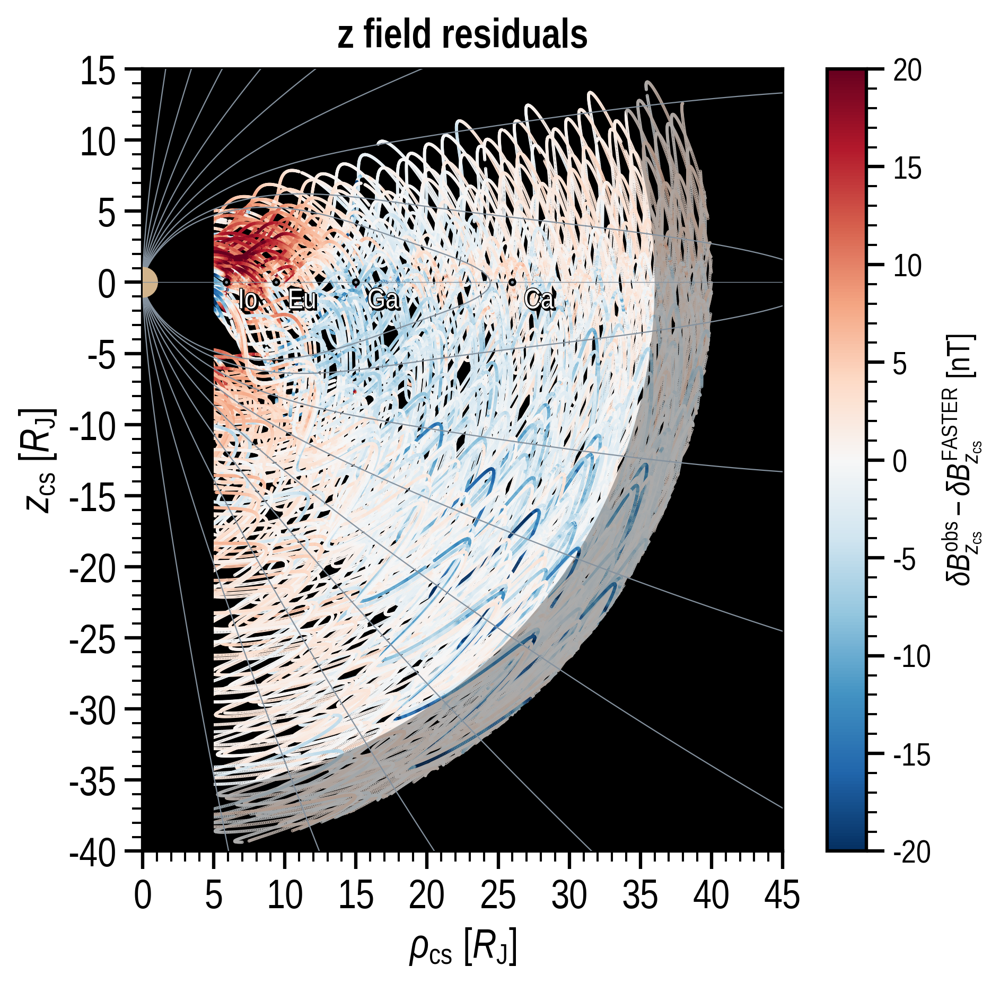

In [19]:
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

# ===========================================================
# Plot settings
# ===========================================================
F = ShareXaxis()
F.fontsize = 17
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(6.2, 5.5), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\rho_{\rm cs}$ [$R_{\rm J}$]',
            min=0.0, max=40.0,
            ticks=np.arange(0, 45+1, 5),
            ticklabels=np.arange(0, 45+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-40.0, max=15.0,
            ticks=np.arange(-40, 15+1, 5),
            ticklabels=np.arange(-40, 15+1, 5, dtype=int),
            minor_num=5,)
F.ax.set_facecolor('k')
cmap = plt.get_cmap('RdBu_r')

# ===========================================================
# Color coded plot
# ===========================================================
F.ax.scatter(rho_cs_5_36,
             z_cs_5_36,
             c=Bz_cs_res_5_36,
             vmin=-20, vmax=20, cmap=cmap,
             s=0.1,)

# ===========================================================
# Dummy
# ===========================================================
sc = F.ax.scatter(-999.9,
                  -999.9,
                  c=0.0,
                  vmin=-20, vmax=20, cmap=cmap,
                  s=0.6,)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]-7):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_N[i, 2, :],
              linewidth=0.5, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_S[i, 2, :],
              linewidth=0.5, color=UC.gray, zorder=5)

# ===========================================================
# Jupiter
# ===========================================================
F.ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                          zorder=6, fill=True, clip_on=True))

# ===========================================================
# Galilean moons
# ===========================================================
F.ax.axhline(y=0.0, color=UC.gray, linewidth=0.3, zorder=7)
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-1.1, -1.1, -1.1, -1.1]
for i in range(len(radii)):
    F.ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                              zorder=8, fill=True, clip_on=True))
    F.textbox(ax_idx=0,
              x=radii[i]+0.8, y=labelz[i],
              text=name[i],
              textedge=True,
              fontsize=F.fontsize*0.7,
              facealpha=0.0,
              edgecolor='none',
              zorder=8)

# ===========================================================
# Hatch mask outside 36 RJ
# ===========================================================
for r_in, r_out in [(36, 41)]:
    # 上半分（z_cs > 0, つまり角度0-180度）
    wedge_top = Wedge(
        center=(0, 0),      # 木星の位置
        r=r_out,            # 外半径
        theta1=0,           # 開始角度
        theta2=360,         # 終了角度
        width=r_out - r_in,  # 幅 = 4 RJ
        facecolor='k',
        edgecolor=None,
        alpha=0.30,
        linewidth=0.5,
        transform=F.ax.transData,
        zorder=4.9,
    )
    F.ax.add_patch(wedge_top)
F.ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)

# ===========================================================
# Colorbar
# ===========================================================
cax = F.fig.colorbar(sc, ax=F.ax)
cax.ax.set_yticks(np.arange(-20, 20+1, 5))
cax.ax.set_yticklabels(np.arange(-20, 20+1, 5, dtype=int),
                       fontsize=F.fontsize*0.8)
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
cax.ax.set_ylabel(
    r'$\delta B_{z_{\rm cs}}^{\rm obs}-\delta B_{z_{\rm cs}}^{\rm FASTER}$ [nT]',
    fontsize=F.fontsize*0.8)

F.ax.set_title('z field residuals', weight='bold')

Text(0.5, 1.01, 'Azimuthal field component residuals')

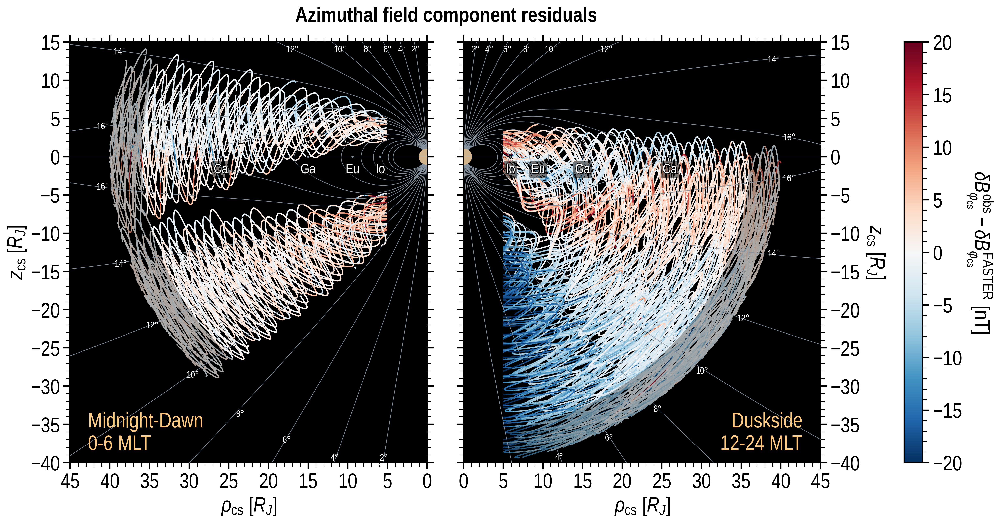

In [20]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.5,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)


# ===========================================================
# Color coded plot
# ===========================================================
dawn_idx = np.where(JunoMLT_5_36 <= 12.0)
ax.scatter(rho_cs_5_36[dawn_idx],
           z_cs_5_36[dawn_idx],
           c=Bphi_cs_res_5_36[dawn_idx],
           vmin=-20, vmax=20, cmap=cmap,
           s=0.2,)

# ===========================================================
# Dummy
# ===========================================================
sc = ax.scatter(-999.9,
                -999.9,
                c=0.0,
                vmin=-20, vmax=20, cmap=cmap,
                s=0.6,)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')


# ===========================================================
# Color coded plot
# ===========================================================
dusk_idx = np.where(JunoMLT_5_36 > 12.0)
ax.scatter(rho_cs_5_36[dusk_idx],
           z_cs_5_36[dusk_idx],
           c=Bphi_cs_res_5_36[dusk_idx],
           vmin=-20, vmax=20, cmap=cmap,
           s=0.2,)

# ===========================================================
# Dummy
# ===========================================================
sc = ax.scatter(-999.9,
                -999.9,
                c=0.0,
                vmin=-20, vmax=20, cmap=cmap,
                s=0.6,)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(sc, cax=cax)
pp.ax.set_yticks(np.arange(-20, 20+1, 5))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\delta B_{\varphi_{\rm cs}}^{\rm obs}-\delta B_{\varphi_{\rm cs}}^{\rm FASTER}$ [nT]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle('Azimuthal field component residuals', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

Text(0.5, 1.01, 'Radial field component residuals')

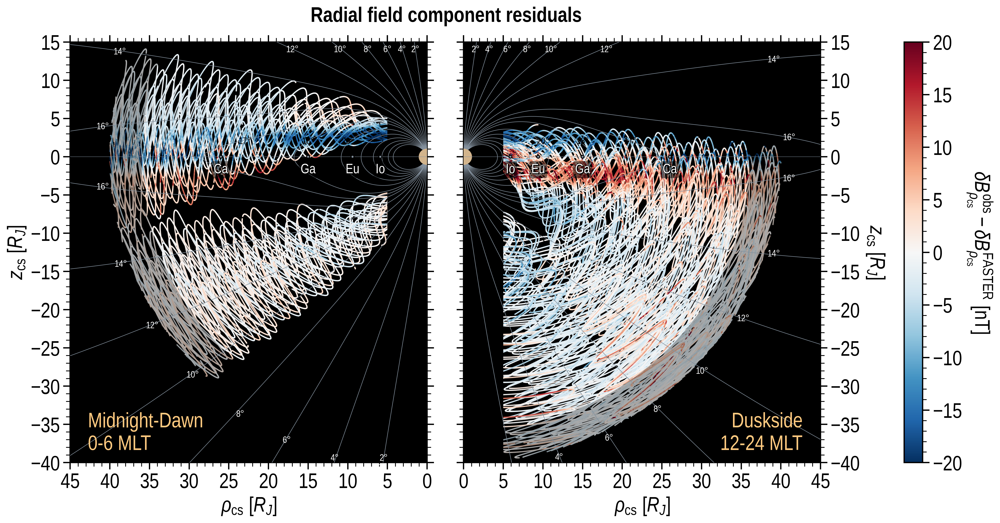

In [21]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.5,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)


# ===========================================================
# Color coded plot
# ===========================================================
dawn_idx = np.where(JunoMLT_5_36 <= 12.0)
ax.scatter(rho_cs_5_36[dawn_idx],
           z_cs_5_36[dawn_idx],
           c=Brho_cs_res_5_36[dawn_idx],
           vmin=-20, vmax=20, cmap=cmap,
           s=0.2,)

# ===========================================================
# Dummy
# ===========================================================
sc = ax.scatter(-999.9,
                -999.9,
                c=0.0,
                vmin=-20, vmax=20, cmap=cmap,
                s=0.6,)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')


# ===========================================================
# Color coded plot
# ===========================================================
dusk_idx = np.where(JunoMLT_5_36 > 12.0)
ax.scatter(rho_cs_5_36[dusk_idx],
           z_cs_5_36[dusk_idx],
           c=Brho_cs_res_5_36[dusk_idx],
           vmin=-20, vmax=20, cmap=cmap,
           s=0.2,)

# ===========================================================
# Dummy
# ===========================================================
sc = ax.scatter(-999.9,
                -999.9,
                c=0.0,
                vmin=-20, vmax=20, cmap=cmap,
                s=0.6,)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(sc, cax=cax)
pp.ax.set_yticks(np.arange(-20, 20+1, 5))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\delta B_{\rho_{\rm cs}}^{\rm obs}-\delta B_{\rho_{\rm cs}}^{\rm FASTER}$ [nT]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle('Radial field component residuals', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

Text(0.5, 1.01, 'Radial field component observation')

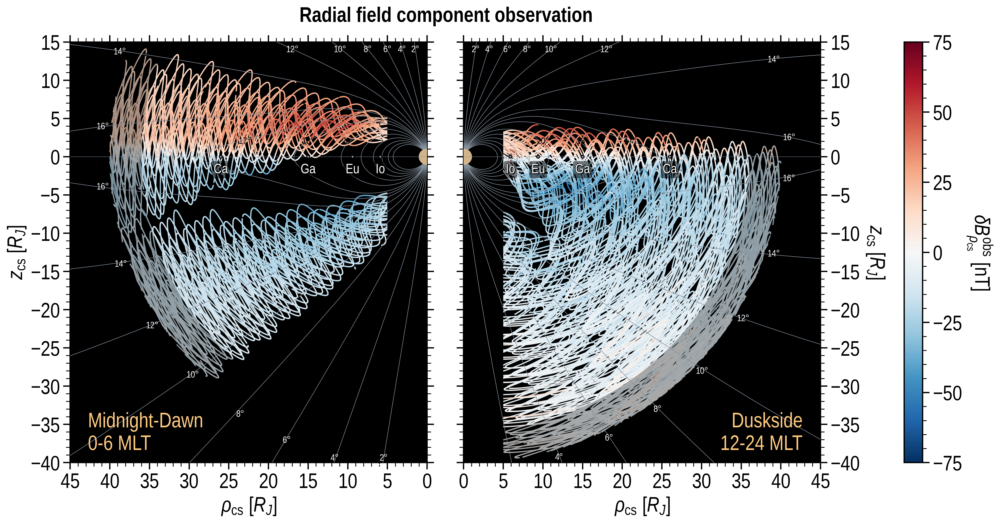

In [22]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.5,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)


# ===========================================================
# Color coded plot
# ===========================================================
dawn_idx = np.where(JunoMLT_5_36 <= 12.0)
ax.scatter(rho_cs_5_36[dawn_idx],
           z_cs_5_36[dawn_idx],
           c=dBrho_cs_5_36[dawn_idx],
           vmin=-75, vmax=75, cmap=cmap,
           s=0.2,)

# ===========================================================
# Dummy
# ===========================================================
sc = ax.scatter(-999.9,
                -999.9,
                c=0.0,
                vmin=-75, vmax=75, cmap=cmap,
                s=0.6,)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')


# ===========================================================
# Color coded plot
# ===========================================================
dusk_idx = np.where(JunoMLT_5_36 > 12.0)
ax.scatter(rho_cs_5_36[dusk_idx],
           z_cs_5_36[dusk_idx],
           c=dBrho_cs_5_36[dusk_idx],
           vmin=-75, vmax=75, cmap=cmap,
           s=0.2,)

# ===========================================================
# Dummy
# ===========================================================
sc = ax.scatter(-999.9,
                -999.9,
                c=0.0,
                vmin=-75, vmax=75, cmap=cmap,
                s=0.6,)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(sc, cax=cax)
pp.ax.set_yticks(np.arange(-75, 75+1, 25))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\delta B_{\rho_{\rm cs}}^{\rm obs}$ [nT]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle('Radial field component observation', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

Text(0.5, 1.01, 'z field component residuals')

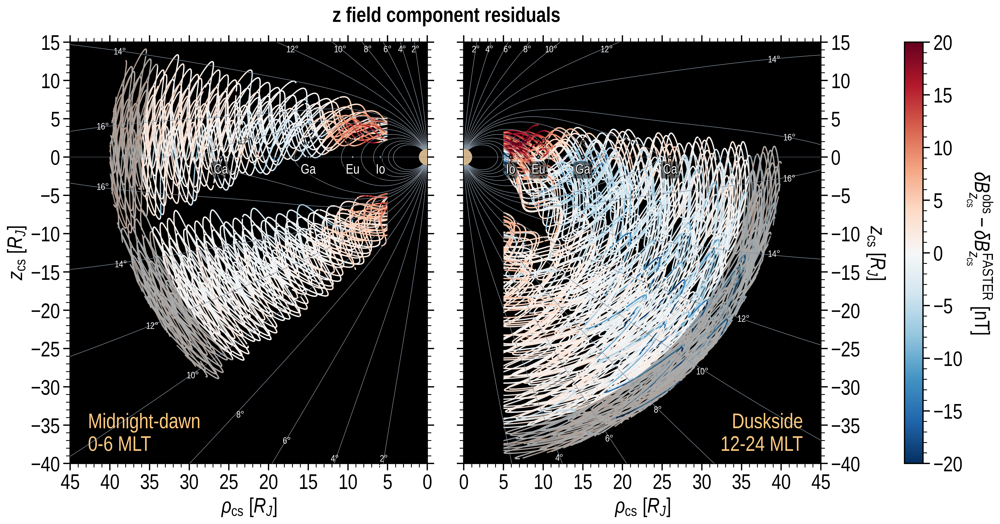

In [23]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.5,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)


# ===========================================================
# Color coded plot
# ===========================================================
dawn_idx = np.where(JunoMLT_5_36 <= 12.0)
ax.scatter(rho_cs_5_36[dawn_idx],
           z_cs_5_36[dawn_idx],
           c=Bz_cs_res_5_36[dawn_idx],
           vmin=-20, vmax=20, cmap=cmap,
           s=0.2,)

# ===========================================================
# Dummy
# ===========================================================
sc = ax.scatter(-999.9,
                -999.9,
                c=0.0,
                vmin=-20, vmax=20, cmap=cmap,
                s=0.6,)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')


# ===========================================================
# Color coded plot
# ===========================================================
dusk_idx = np.where(JunoMLT_5_36 > 12.0)
ax.scatter(rho_cs_5_36[dusk_idx],
           z_cs_5_36[dusk_idx],
           c=Bz_cs_res_5_36[dusk_idx],
           vmin=-20, vmax=20, cmap=cmap,
           s=0.2,)

# ===========================================================
# Dummy
# ===========================================================
sc = ax.scatter(-999.9,
                -999.9,
                c=0.0,
                vmin=-20, vmax=20, cmap=cmap,
                s=0.6,)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(sc, cax=cax)
pp.ax.set_yticks(np.arange(-20, 20+1, 5))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\delta B_{z_{\rm cs}}^{\rm obs}-\delta B_{z_{\rm cs}}^{\rm FASTER}$ [nT]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle('z field component residuals', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

# Dawnside

In [24]:
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)

# ===========================================================
# Create a grid
# ===========================================================
dawn_idx = np.where(JunoMLT_5_36 <= 12.0)
d_rj = 0.5
grid_rho_cs = np.arange(1.0, 45.0+1, d_rj)
grid_z_cs = np.arange(-40.0, 15.0+1, d_rj)
RHO_CS, Z_CS = np.meshgrid(grid_rho_cs, grid_z_cs)   # shape (Nz, Nrho)
points = np.column_stack([
    rho_cs_5_36[dawn_idx],
    z_cs_5_36[dawn_idx]])  # shape (N, 2)


# ----------------------------------------------------------
# 1. 散布点 → 2D グリッドに補間
# ----------------------------------------------------------
def interp(values):
    grid = griddata(points, values, (RHO_CS, Z_CS), method='linear')
    grid_nn = griddata(points, values, (RHO_CS, Z_CS), method='nearest')
    mask = np.isnan(grid)
    grid[mask] = grid_nn[mask]
    return grid


dBrho_cs_res_g = interp(Brho_cs_res_5_36[dawn_idx])
dBphi_cs_res_g = interp(Bphi_cs_res_5_36[dawn_idx])
dBz_cs_res_g = interp(Bz_cs_res_5_36[dawn_idx])

# カバレッジマスク
_ones = np.ones(len(rho_cs_5_36[dawn_idx]))
mask_coverage = griddata(points, _ones, (RHO_CS, Z_CS), method='linear')
outside_mask = np.isnan(mask_coverage)

# KDTreeマスク
tree = KDTree(np.column_stack([rho_cs_5_36[dawn_idx], z_cs_5_36[dawn_idx]]))
nn_dist, _ = tree.query(np.column_stack([RHO_CS.ravel(), Z_CS.ravel()]))
nn_dist_grid = nn_dist.reshape(RHO_CS.shape)
outside_mask = outside_mask | (nn_dist_grid > 0.5)

# 平滑化の前にマスク領域をnanに戻す
dBrho_cs_res_g[outside_mask] = np.nan
dBphi_cs_res_g[outside_mask] = np.nan
dBz_cs_res_g[outside_mask] = np.nan


# ----------------------------------------------------------
# 2. 平滑化（マスク境界を考慮）
# ----------------------------------------------------------
smooth_sigma = 1.0 / d_rj


def smooth_with_mask(data, sigma, mask):
    data_filled = data.copy()
    data_filled[mask] = 0.0
    smoothed = gaussian_filter(data_filled, sigma=sigma)
    weight = np.ones_like(data)
    weight[mask] = 0.0
    weight_smoothed = gaussian_filter(weight, sigma=sigma)
    return np.where(weight_smoothed > 0.01, smoothed / weight_smoothed, 0.0)


dBrho_g = smooth_with_mask(dBrho_cs_res_g, smooth_sigma, outside_mask)
dBphi_g = smooth_with_mask(dBphi_cs_res_g, smooth_sigma, outside_mask)
dBz_g = smooth_with_mask(dBz_cs_res_g,   smooth_sigma, outside_mask)


# ----------------------------------------------------------
# 3. 数値微分: ∂/∂ρ, ∂/∂z  [nT/RJ]
# ----------------------------------------------------------
drho = np.gradient(grid_rho_cs)   # shape (Nrho,)
dz = np.gradient(grid_z_cs)     # shape (Nz,)

# np.gradient は各軸方向に微分: axis=1 → ρ方向, axis=0 → z方向
# dBphi_g: shape (Nz, Nrho)

# ∂(dBφ)/∂z  [nT/RJ]
ddBphi_dz = np.gradient(dBphi_g,  grid_z_cs,   axis=0)
# ∂(dBφ)/∂ρ  [nT/RJ]
ddBphi_drho = np.gradient(dBphi_g, grid_rho_cs, axis=1)
# ∂(ρ·dBφ)/∂ρ = dBφ + ρ·∂dBφ/∂ρ   [nT/RJ]
rho_ddBphi_drho = dBphi_g + RHO_CS * ddBphi_drho

# ∂(dBρ)/∂z  [nT/RJ]
ddBrho_dz = np.gradient(dBrho_g,  grid_z_cs,   axis=0)
# ∂(dBz)/∂ρ  [nT/RJ]
ddBz_drho = np.gradient(dBz_g,    grid_rho_cs, axis=1)


# ----------------------------------------------------------
# 4. 電流密度 J = rot(dB) / μ0   (軸対称仮定: ∂/∂φ = 0)
# ----------------------------------------------------------
# 単位変換: nT/RJ → T/m = nT/RJ * 1e-9 / (RJ_in_m)
# J [A/m²] = (1/μ0) * (nT/RJ) * 1e-9 / RJ_m
conv = 1E-9 / (RJ * MU0)   # [A/m² per (nT/RJ)]

# J_ρ = -(1/μ0) ∂(dBφ)/∂z
J_rho_grid = -ddBphi_dz * conv               # [A/m²]

# J_φ = (1/μ0) (∂dBρ/∂z - ∂dBz/∂ρ)
J_phi_grid = (ddBrho_dz - ddBz_drho) * conv  # [A/m²]

# J_z = (1/μ₀ρ) ∂(ρ·dBφ)/∂ρ
# ρ=0 の特異点を避ける (ρ > 0.5 RJ)
rho_safe = np.where(RHO_CS > 0.5, RHO_CS, 0.5)
J_z_grid = rho_ddBphi_drho / rho_safe * conv  # [A/m²]

# nA/m² に変換 (見やすい単位)
J_rho_grid *= 1E+9
J_phi_grid *= 1E+9
J_z_grid *= 1E+9


# ----------------------------------------------------------
# 5. 背景磁場方向 B̂ を取得して J∥ を計算
# ----------------------------------------------------------
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
csfield = CSField()
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)
Nz_g, Nrho_g = RHO_CS.shape
b_rho = np.zeros(RHO_CS.shape)
b_phi = np.zeros(RHO_CS.shape)
b_z = np.zeros(RHO_CS.shape)

# R: SIII直交 → CS直交
theta_d = math.radians(csfield.theta_d_deg)
phi_d = math.radians(csfield.phi_d_deg)
R = np.array([
    [math.cos(theta_d)*math.cos(phi_d),  math.cos(theta_d)
     * math.sin(phi_d), -math.sin(theta_d)],
    [-math.sin(phi_d),
     math.cos(phi_d),                    0.0],
    [math.sin(theta_d)*math.cos(phi_d),  math.sin(theta_d)
     * math.sin(phi_d),  math.cos(theta_d)]
])

# RT: CS直交 → SIII直交 (Rの転置 = Rの逆行列、直交行列なので)
RT = R.T

phi_0 = math.radians(360.0-112.0)

for iz in range(Nz_g):
    for ir in range(Nrho_g):
        rho_0 = RHO_CS[iz, ir]
        z_0 = Z_CS[iz, ir]

        x_cs = rho_0 * math.cos(phi_0)
        y_cs = rho_0 * math.sin(phi_0)
        z_cs_val = z_0

        pos_siii = RT @ np.array([x_cs, y_cs, z_cs_val])
        x0, y0, z0 = pos_siii[0], pos_siii[1], pos_siii[2]

        try:
            Bx0, By0, Bz0 = jm.Internal.Field(x0, y0, z0)            # [nT]
            Bx1, By1, Bz1 = csfield.magnetic_field_v2(x0, y0, z0, 3.0)  # [T]

            Bx = (Bx0*1E-9)+Bx1     # [T]
            By = (By0*1E-9)+By1     # [T]
            Bz = (Bz0*1E-9)+Bz1     # [T]
            B0 = math.sqrt(Bx**2+By**2+Bz**2)      # [T]

            # SIII直交 → CS直交 (回転行列 R を適用)
            B_siii = np.array([Bx/B0, By/B0, Bz/B0])
            B_cs_cart = R @ B_siii   # CS直交成分

            # CS直交 → CS円柱 (phi_0 は CS座標でのφ角)
            B_rho_cs = B_cs_cart[0] * \
                math.cos(phi_0) + B_cs_cart[1]*math.sin(phi_0)
            B_phi_cs = -B_cs_cart[0] * \
                math.sin(phi_0) + B_cs_cart[1]*math.cos(phi_0)
            B_z_cs = B_cs_cart[2]

            b_rho[iz, ir] = B_rho_cs
            b_phi[iz, ir] = B_phi_cs
            b_z[iz, ir] = B_z_cs

        except:
            b_rho[iz, ir], b_phi[iz, ir], b_z[iz, ir] = np.nan, np.nan, np.nan

J_para = J_rho_grid*b_rho + J_phi_grid*b_phi + J_z_grid*b_z

# データカバレッジ外をマスク
J_para[outside_mask] = np.nan
J_rho_grid[outside_mask] = np.nan
J_phi_grid[outside_mask] = np.nan
J_z_grid[outside_mask] = np.nan

J_para_0060 = J_para
RHO_CS_0060 = RHO_CS
Z_CS_0060 = Z_CS
J_rho_grid_0060 = J_rho_grid
J_phi_grid_0060 = J_phi_grid
J_z_grid_0060 = J_z_grid
dBrho_cs_res_g_0060 = dBrho_cs_res_g
dBphi_cs_res_g_0060 = dBphi_cs_res_g
dBz_cs_res_g_0060 = dBz_cs_res_g

/var/folders/pk/wwq1djys0bs6c1c4hrxq7p3w0000gn/T/ipykernel_36082/2015146859.py:74: RuntimeWarning: invalid value encountered in divide
  return np.where(weight_smoothed > 0.01, smoothed / weight_smoothed, 0.0)


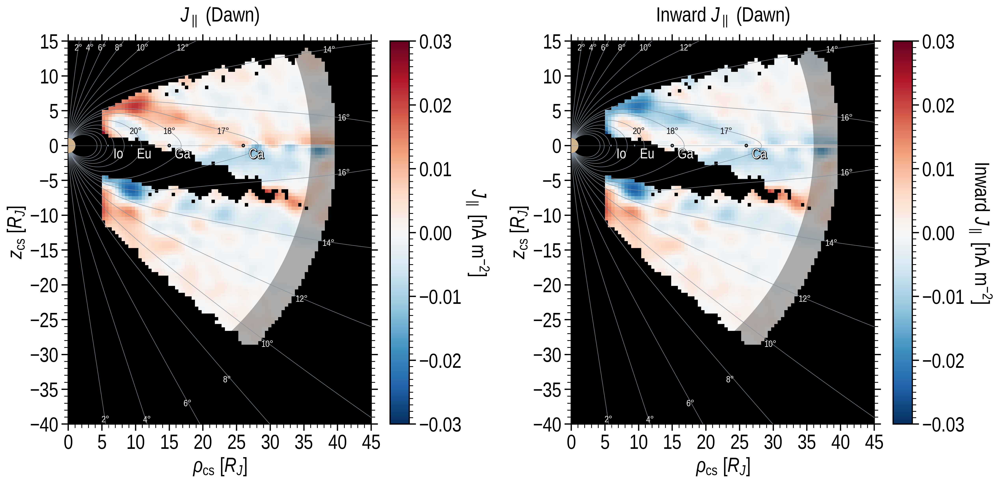

In [25]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')
    ax.tick_params(
        axis='both',       # Apply to both x and y axes
        which='both',      # Apply to both major and minor ticks
        top=True,          # Show top tick marks
        right=True,        # Show right tick marks
    )

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel
# ===========================================================
ax = axes[0]
ax.set_title(r'$J_\parallel$ (Dawn)',
             fontsize=F.fontsize,
             y=1.03)

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    J_para_0060,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_0060.min(), RHO_CS_0060.max(),
        Z_CS_0060.min(),   Z_CS_0060.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.5, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.5, color=UC.gray, zorder=5)

# ===========================================================
# Jupiter
# ===========================================================
ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                        zorder=6, fill=True, clip_on=True))

# ===========================================================
# Galilean moons
# ===========================================================
ax.axhline(y=0.0, color=UC.gray, linewidth=0.3, zorder=7)
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-1.1, -1.1, -1.1, -1.1]
for i in range(len(radii)):
    ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                            zorder=8, fill=True, clip_on=True))
    F.textbox(ax_idx=ax,
              x=radii[i]+0.8, y=labelz[i],
              text=name[i],
              textedge=True,
              fontsize=F.fontsize*0.7,
              facealpha=0.0,
              edgecolor='none',
              zorder=8)

# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()
cax = fig.colorbar(cf, ax=ax)
cax.ax.set_yticks(np.linspace(-0.03, 0.03, 7))
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(10))
cax.ax.set_ylabel(r'$J_\parallel$ [nA m$^{-2}$]',
                  verticalalignment='bottom',
                  rotation=270)


# ===========================================================
# Right panel
# ===========================================================
ax = axes[1]
ax.set_title(r'Inward $J_\parallel$ (Dawn)',
             fontsize=F.fontsize,
             y=1.03)

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    -np.sign(Z_CS_0060)*J_para_0060,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_0060.min(), RHO_CS_0060.max(),
        Z_CS_0060.min(),   Z_CS_0060.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.5, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.5, color=UC.gray, zorder=5)

# ===========================================================
# Jupiter
# ===========================================================
ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                        zorder=6, fill=True, clip_on=True))

# ===========================================================
# Galilean moons
# ===========================================================
ax.axhline(y=0.0, color=UC.gray, linewidth=0.3, zorder=7)
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-1.1, -1.1, -1.1, -1.1]
for i in range(len(radii)):
    ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                            zorder=8, fill=True, clip_on=True))
    F.textbox(ax_idx=ax,
              x=radii[i]+0.8, y=labelz[i],
              text=name[i],
              textedge=True,
              fontsize=F.fontsize*0.7,
              facealpha=0.0,
              edgecolor='none',
              zorder=8)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

for ax in axes:
    lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
    label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
    for i in range(len(lat_deg_list)):
        lat_deg = lat_deg_list[i]
        lat_rad = np.deg2rad(lat_deg)
        rho_i = r_arc * np.cos(lat_rad)
        z_i = r_arc * np.sin(lat_rad)

        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

        ax.text(
            rho_i, z_i, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
    label_list = [2, 4, 6, 8, 10, 12]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], 14, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [5.5]
    label_list = [2]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], -40.0, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='bottom',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [10, 15, 23]
    label_list = [20, 18, 17]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], 2, label,
            fontsize=F.fontsize*0.45,
            color='k',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()
cax = fig.colorbar(cf, ax=ax)
cax.ax.set_yticks(np.linspace(-0.03, 0.03, 7))
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(10))
cax.ax.set_ylabel(r'Inward $J_\parallel$ [nA m$^{-2}$]',
                  verticalalignment='bottom',
                  rotation=270)

fig.tight_layout()

# Duskside

In [26]:
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)

# ===========================================================
# Create a grid
# ===========================================================
dusk_idx = np.where(JunoMLT_5_36 > 12.0)
d_rj = 0.5
grid_rho_cs = np.arange(1.0, 45.0+1, d_rj)
grid_z_cs = np.arange(-40.0, 15.0+1, d_rj)
RHO_CS, Z_CS = np.meshgrid(grid_rho_cs, grid_z_cs)   # shape (Nz, Nrho)
points = np.column_stack([
    rho_cs_5_36[dusk_idx],
    z_cs_5_36[dusk_idx]])  # shape (N, 2)


# ----------------------------------------------------------
# 1. 散布点 → 2D グリッドに補間
# ----------------------------------------------------------
def interp(values):
    grid = griddata(points, values, (RHO_CS, Z_CS), method='linear')
    grid_nn = griddata(points, values, (RHO_CS, Z_CS), method='nearest')
    mask = np.isnan(grid)
    grid[mask] = grid_nn[mask]
    return grid


dBrho_cs_res_g = interp(Brho_cs_res_5_36[dusk_idx])
dBphi_cs_res_g = interp(Bphi_cs_res_5_36[dusk_idx])
dBz_cs_res_g = interp(Bz_cs_res_5_36[dusk_idx])

# カバレッジマスク
_ones = np.ones(len(rho_cs_5_36[dusk_idx]))
mask_coverage = griddata(points, _ones, (RHO_CS, Z_CS), method='linear')
outside_mask = np.isnan(mask_coverage)

# KDTreeマスク
tree = KDTree(np.column_stack([rho_cs_5_36[dusk_idx], z_cs_5_36[dusk_idx]]))
nn_dist, _ = tree.query(np.column_stack([RHO_CS.ravel(), Z_CS.ravel()]))
nn_dist_grid = nn_dist.reshape(RHO_CS.shape)
outside_mask = outside_mask | (nn_dist_grid > 0.5)

# 平滑化の前にマスク領域をnanに戻す
dBrho_cs_res_g[outside_mask] = np.nan
dBphi_cs_res_g[outside_mask] = np.nan
dBz_cs_res_g[outside_mask] = np.nan


# ----------------------------------------------------------
# 2. 平滑化（マスク境界を考慮）
# ----------------------------------------------------------
smooth_sigma = 1.0 / d_rj


def smooth_with_mask(data, sigma, mask):
    data_filled = data.copy()
    data_filled[mask] = 0.0
    smoothed = gaussian_filter(data_filled, sigma=sigma)
    weight = np.ones_like(data)
    weight[mask] = 0.0
    weight_smoothed = gaussian_filter(weight, sigma=sigma)
    return np.where(weight_smoothed > 0.01, smoothed / weight_smoothed, 0.0)


dBrho_g = smooth_with_mask(dBrho_cs_res_g, smooth_sigma, outside_mask)
dBphi_g = smooth_with_mask(dBphi_cs_res_g, smooth_sigma, outside_mask)
dBz_g = smooth_with_mask(dBz_cs_res_g,   smooth_sigma, outside_mask)


# ----------------------------------------------------------
# 3. 数値微分: ∂/∂ρ, ∂/∂z  [nT/RJ]
# ----------------------------------------------------------
drho = np.gradient(grid_rho_cs)   # shape (Nrho,)
dz = np.gradient(grid_z_cs)     # shape (Nz,)

# np.gradient は各軸方向に微分: axis=1 → ρ方向, axis=0 → z方向
# dBphi_g: shape (Nz, Nrho)

# ∂(dBφ)/∂z  [nT/RJ]
ddBphi_dz = np.gradient(dBphi_g,  grid_z_cs,   axis=0)
# ∂(dBφ)/∂ρ  [nT/RJ]
ddBphi_drho = np.gradient(dBphi_g, grid_rho_cs, axis=1)
# ∂(ρ·dBφ)/∂ρ = dBφ + ρ·∂dBφ/∂ρ   [nT/RJ]
rho_ddBphi_drho = dBphi_g + RHO_CS * ddBphi_drho

# ∂(dBρ)/∂z  [nT/RJ]
ddBrho_dz = np.gradient(dBrho_g,  grid_z_cs,   axis=0)
# ∂(dBz)/∂ρ  [nT/RJ]
ddBz_drho = np.gradient(dBz_g,    grid_rho_cs, axis=1)


# ----------------------------------------------------------
# 4. 電流密度 J = rot(dB) / μ0   (軸対称仮定: ∂/∂φ = 0)
# ----------------------------------------------------------
# 単位変換: nT/RJ → T/m = nT/RJ * 1e-9 / (RJ_in_m)
# J [A/m²] = (1/μ0) * (nT/RJ) * 1e-9 / RJ_m
conv = 1E-9 / (RJ * MU0)   # [A/m² per (nT/RJ)]

# J_ρ = -(1/μ0) ∂(dBφ)/∂z
J_rho_grid = -ddBphi_dz * conv               # [A/m²]

# J_φ = (1/μ0) (∂dBρ/∂z - ∂dBz/∂ρ)
J_phi_grid = (ddBrho_dz - ddBz_drho) * conv  # [A/m²]

# J_z = (1/μ₀ρ) ∂(ρ·dBφ)/∂ρ
# ρ=0 の特異点を避ける (ρ > 0.5 RJ)
rho_safe = np.where(RHO_CS > 0.5, RHO_CS, 0.5)
J_z_grid = rho_ddBphi_drho / rho_safe * conv  # [A/m²]

# nA/m² に変換 (見やすい単位)
J_rho_grid *= 1E+9
J_phi_grid *= 1E+9
J_z_grid *= 1E+9


# ----------------------------------------------------------
# 5. 背景磁場方向 B̂ を取得して J∥ を計算
# ----------------------------------------------------------
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
csfield = CSField()
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)
Nz_g, Nrho_g = RHO_CS.shape
b_rho = np.zeros(RHO_CS.shape)
b_phi = np.zeros(RHO_CS.shape)
b_z = np.zeros(RHO_CS.shape)

# R: SIII直交 → CS直交
theta_d = math.radians(csfield.theta_d_deg)
phi_d = math.radians(csfield.phi_d_deg)
R = np.array([
    [math.cos(theta_d)*math.cos(phi_d),  math.cos(theta_d)
     * math.sin(phi_d), -math.sin(theta_d)],
    [-math.sin(phi_d),
     math.cos(phi_d),                    0.0],
    [math.sin(theta_d)*math.cos(phi_d),  math.sin(theta_d)
     * math.sin(phi_d),  math.cos(theta_d)]
])

# RT: CS直交 → SIII直交 (Rの転置 = Rの逆行列、直交行列なので)
RT = R.T

phi_0 = math.radians(360.0-112.0)

for iz in range(Nz_g):
    for ir in range(Nrho_g):
        rho_0 = RHO_CS[iz, ir]
        z_0 = Z_CS[iz, ir]

        x_cs = rho_0 * math.cos(phi_0)
        y_cs = rho_0 * math.sin(phi_0)
        z_cs_val = z_0

        pos_siii = RT @ np.array([x_cs, y_cs, z_cs_val])
        x0, y0, z0 = pos_siii[0], pos_siii[1], pos_siii[2]

        try:
            Bx0, By0, Bz0 = jm.Internal.Field(x0, y0, z0)            # [nT]
            Bx1, By1, Bz1 = csfield.magnetic_field_v2(x0, y0, z0, 18.0)  # [T]

            Bx = (Bx0*1E-9)+Bx1     # [T]
            By = (By0*1E-9)+By1     # [T]
            Bz = (Bz0*1E-9)+Bz1     # [T]
            B0 = math.sqrt(Bx**2+By**2+Bz**2)      # [T]

            # SIII直交 → CS直交 (回転行列 R を適用)
            B_siii = np.array([Bx/B0, By/B0, Bz/B0])
            B_cs_cart = R @ B_siii   # CS直交成分

            # CS直交 → CS円柱 (phi_0 は CS座標でのφ角)
            B_rho_cs = B_cs_cart[0] * \
                math.cos(phi_0) + B_cs_cart[1]*math.sin(phi_0)
            B_phi_cs = -B_cs_cart[0] * \
                math.sin(phi_0) + B_cs_cart[1]*math.cos(phi_0)
            B_z_cs = B_cs_cart[2]

            b_rho[iz, ir] = B_rho_cs
            b_phi[iz, ir] = B_phi_cs
            b_z[iz, ir] = B_z_cs

        except:
            b_rho[iz, ir], b_phi[iz, ir], b_z[iz, ir] = np.nan, np.nan, np.nan

J_para = J_rho_grid*b_rho + J_phi_grid*b_phi + J_z_grid*b_z

# データカバレッジ外をマスク
J_para[outside_mask] = np.nan
J_rho_grid[outside_mask] = np.nan
J_phi_grid[outside_mask] = np.nan
J_z_grid[outside_mask] = np.nan

J_para_1224 = J_para
RHO_CS_1224 = RHO_CS
Z_CS_1224 = Z_CS
J_rho_grid_1224 = J_rho_grid
J_phi_grid_1224 = J_phi_grid
J_z_grid_1224 = J_z_grid
dBrho_cs_res_g_1224 = dBrho_cs_res_g
dBphi_cs_res_g_1224 = dBphi_cs_res_g
dBz_cs_res_g_1224 = dBz_cs_res_g

/var/folders/pk/wwq1djys0bs6c1c4hrxq7p3w0000gn/T/ipykernel_36082/1545697664.py:74: RuntimeWarning: invalid value encountered in divide
  return np.where(weight_smoothed > 0.01, smoothed / weight_smoothed, 0.0)


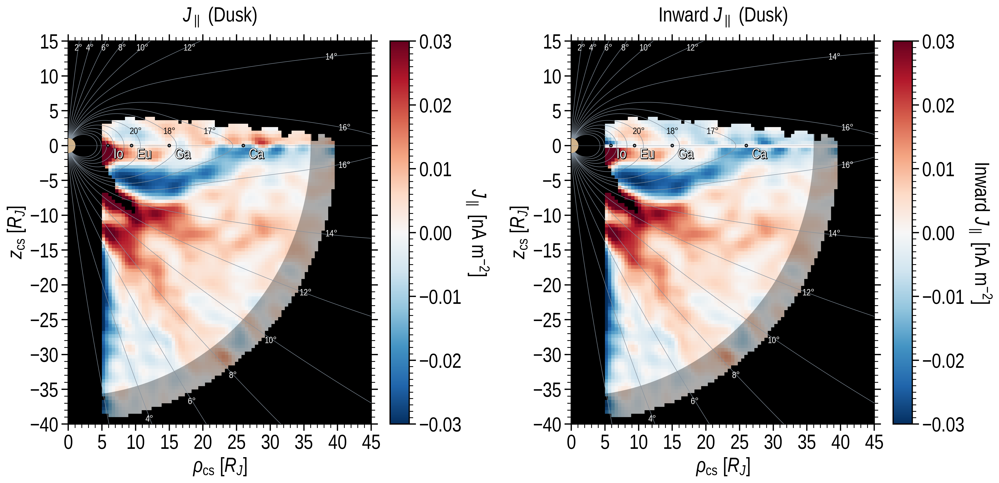

In [27]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')
    ax.tick_params(
        axis='both',       # Apply to both x and y axes
        which='both',      # Apply to both major and minor ticks
        top=True,          # Show top tick marks
        right=True,        # Show right tick marks
    )

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)

# ===========================================================
# Left panel
# ===========================================================
ax = axes[0]
ax.set_title(r'$J_\parallel$ (Dusk)',
             fontsize=F.fontsize,
             y=1.03)

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    J_para_1224,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1224.min(), RHO_CS_1224.max(),
        Z_CS_1224.min(),   Z_CS_1224.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.5, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.5, color=UC.gray, zorder=5)

# ===========================================================
# Jupiter
# ===========================================================
ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                        zorder=6, fill=True, clip_on=True))

# ===========================================================
# Galilean moons
# ===========================================================
ax.axhline(y=0.0, color=UC.gray, linewidth=0.3, zorder=7)
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-1.1, -1.1, -1.1, -1.1]
for i in range(len(radii)):
    ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                            zorder=8, fill=True, clip_on=True))
    F.textbox(ax_idx=ax,
              x=radii[i]+0.8, y=labelz[i],
              text=name[i],
              textedge=True,
              fontsize=F.fontsize*0.7,
              facealpha=0.0,
              edgecolor='none',
              zorder=8)

# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()
cax = fig.colorbar(cf, ax=ax)
cax.ax.set_yticks(np.linspace(-0.03, 0.03, 7))
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(10))
cax.ax.set_ylabel(r'$J_\parallel$ [nA m$^{-2}$]',
                  verticalalignment='bottom',
                  rotation=270)


# ===========================================================
# Right panel
# ===========================================================
ax = axes[1]
ax.set_title(r'Inward $J_\parallel$ (Dusk)',
             fontsize=F.fontsize,
             y=1.03)

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    -np.sign(Z_CS_1224)*J_para_1224,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1224.min(), RHO_CS_1224.max(),
        Z_CS_1224.min(),   Z_CS_1224.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.5, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.5, color=UC.gray, zorder=5)

# ===========================================================
# Jupiter
# ===========================================================
ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                        zorder=6, fill=True, clip_on=True))

# ===========================================================
# Galilean moons
# ===========================================================
ax.axhline(y=0.0, color=UC.gray, linewidth=0.3, zorder=7)
radii = [5.9, 9.4, 15.0, 26.0]
name = ['Io', 'Eu', 'Ga', 'Ca']
labelz = [-1.1, -1.1, -1.1, -1.1]
for i in range(len(radii)):
    ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                            zorder=8, fill=True, clip_on=True))
    F.textbox(ax_idx=ax,
              x=radii[i]+0.8, y=labelz[i],
              text=name[i],
              textedge=True,
              fontsize=F.fontsize*0.7,
              facealpha=0.0,
              edgecolor='none',
              zorder=8)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

for ax in axes:
    lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
    label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
    for i in range(len(lat_deg_list)):
        lat_deg = lat_deg_list[i]
        lat_rad = np.deg2rad(lat_deg)
        rho_i = r_arc * np.cos(lat_rad)
        z_i = r_arc * np.sin(lat_rad)

        # プロット範囲内のみ描画
        if not (rho_min <= rho_i <= rho_max and z_min <= z_i <= z_max):
            continue

        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

        ax.text(
            rho_i, z_i, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
    label_list = [2, 4, 6, 8, 10, 12]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], 14, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [10, 15, 21]
    label_list = [20, 18, 17]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], 2, label,
            fontsize=F.fontsize*0.45,
            color='k',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()
cax = fig.colorbar(cf, ax=ax)
cax.ax.set_yticks(np.linspace(-0.03, 0.03, 7))
cax.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(10))
cax.ax.set_ylabel(r'Inward $J_\parallel$ [nA m$^{-2}$]',
                  verticalalignment='bottom',
                  rotation=270)

fig.tight_layout()

In [28]:
# Dusk側のデータ点を南半球高緯度領域に絞って確認
dusk_sparse_idx = np.where(
    (JunoMLT_5_36 > 12.0) &
    (z_cs_5_36 < -15.0) &
    (rho_cs_5_36 < 10.0)
)[0]

print(f"該当データ点数: {len(dusk_sparse_idx)}")
print(
    f"rho_cs範囲: {rho_cs_5_36[dusk_sparse_idx].min():.1f} – {rho_cs_5_36[dusk_sparse_idx].max():.1f} RJ")
print(
    f"z_cs範囲: {z_cs_5_36[dusk_sparse_idx].min():.1f} – {z_cs_5_36[dusk_sparse_idx].max():.1f} RJ")

該当データ点数: 12874
rho_cs範囲: 2.9 – 10.0 RJ
z_cs範囲: -39.4 – -15.0 RJ


# Dusk 12-18 & 18-24

In [29]:
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)

# ===========================================================
# Create a grid
# ===========================================================
dusk_idx = np.where((JunoMLT_5_36 > 12.0) & (JunoMLT_5_36 <= 18.0))
d_rj = 0.5
grid_rho_cs = np.arange(1.0, 45.0+1, d_rj)
grid_z_cs = np.arange(-40.0, 15.0+1, d_rj)
RHO_CS, Z_CS = np.meshgrid(grid_rho_cs, grid_z_cs)   # shape (Nz, Nrho)
points = np.column_stack([
    rho_cs_5_36[dusk_idx],
    z_cs_5_36[dusk_idx]])  # shape (N, 2)


# ----------------------------------------------------------
# 1. 散布点 → 2D グリッドに補間
# ----------------------------------------------------------
def interp(values):
    grid = griddata(points, values, (RHO_CS, Z_CS), method='linear')
    grid_nn = griddata(points, values, (RHO_CS, Z_CS), method='nearest')
    mask = np.isnan(grid)
    grid[mask] = grid_nn[mask]
    return grid


dBrho_cs_res_g = interp(Brho_cs_res_5_36[dusk_idx])
dBphi_cs_res_g = interp(Bphi_cs_res_5_36[dusk_idx])
dBz_cs_res_g = interp(Bz_cs_res_5_36[dusk_idx])

# カバレッジマスク
_ones = np.ones(len(rho_cs_5_36[dusk_idx]))
mask_coverage = griddata(points, _ones, (RHO_CS, Z_CS), method='linear')
outside_mask = np.isnan(mask_coverage)

# KDTreeマスク
tree = KDTree(np.column_stack([rho_cs_5_36[dusk_idx], z_cs_5_36[dusk_idx]]))
nn_dist, _ = tree.query(np.column_stack([RHO_CS.ravel(), Z_CS.ravel()]))
nn_dist_grid = nn_dist.reshape(RHO_CS.shape)
outside_mask = outside_mask | (nn_dist_grid > 0.5)

# 平滑化の前にマスク領域をnanに戻す
dBrho_cs_res_g[outside_mask] = np.nan
dBphi_cs_res_g[outside_mask] = np.nan
dBz_cs_res_g[outside_mask] = np.nan


# ----------------------------------------------------------
# 2. 平滑化（マスク境界を考慮）
# ----------------------------------------------------------
smooth_sigma = 1.0 / d_rj


def smooth_with_mask(data, sigma, mask):
    data_filled = data.copy()
    data_filled[mask] = 0.0
    smoothed = gaussian_filter(data_filled, sigma=sigma)
    weight = np.ones_like(data)
    weight[mask] = 0.0
    weight_smoothed = gaussian_filter(weight, sigma=sigma)
    return np.where(weight_smoothed > 0.01, smoothed / weight_smoothed, 0.0)


dBrho_g = smooth_with_mask(dBrho_cs_res_g, smooth_sigma, outside_mask)
dBphi_g = smooth_with_mask(dBphi_cs_res_g, smooth_sigma, outside_mask)
dBz_g = smooth_with_mask(dBz_cs_res_g,   smooth_sigma, outside_mask)


# ----------------------------------------------------------
# 3. 数値微分: ∂/∂ρ, ∂/∂z  [nT/RJ]
# ----------------------------------------------------------
drho = np.gradient(grid_rho_cs)   # shape (Nrho,)
dz = np.gradient(grid_z_cs)     # shape (Nz,)

# np.gradient は各軸方向に微分: axis=1 → ρ方向, axis=0 → z方向
# dBphi_g: shape (Nz, Nrho)

# ∂(dBφ)/∂z  [nT/RJ]
ddBphi_dz = np.gradient(dBphi_g,  grid_z_cs,   axis=0)
# ∂(dBφ)/∂ρ  [nT/RJ]
ddBphi_drho = np.gradient(dBphi_g, grid_rho_cs, axis=1)
# ∂(ρ·dBφ)/∂ρ = dBφ + ρ·∂dBφ/∂ρ   [nT/RJ]
rho_ddBphi_drho = dBphi_g + RHO_CS * ddBphi_drho

# ∂(dBρ)/∂z  [nT/RJ]
ddBrho_dz = np.gradient(dBrho_g,  grid_z_cs,   axis=0)
# ∂(dBz)/∂ρ  [nT/RJ]
ddBz_drho = np.gradient(dBz_g,    grid_rho_cs, axis=1)


# ----------------------------------------------------------
# 4. 電流密度 J = rot(dB) / μ0   (軸対称仮定: ∂/∂φ = 0)
# ----------------------------------------------------------
# 単位変換: nT/RJ → T/m = nT/RJ * 1e-9 / (RJ_in_m)
# J [A/m²] = (1/μ0) * (nT/RJ) * 1e-9 / RJ_m
conv = 1E-9 / (RJ * MU0)   # [A/m² per (nT/RJ)]

# J_ρ = -(1/μ0) ∂(dBφ)/∂z
J_rho_grid = -ddBphi_dz * conv               # [A/m²]

# J_φ = (1/μ0) (∂dBρ/∂z - ∂dBz/∂ρ)
J_phi_grid = (ddBrho_dz - ddBz_drho) * conv  # [A/m²]

# J_z = (1/μ₀ρ) ∂(ρ·dBφ)/∂ρ
# ρ=0 の特異点を避ける (ρ > 0.5 RJ)
rho_safe = np.where(RHO_CS > 0.5, RHO_CS, 0.5)
J_z_grid = rho_ddBphi_drho / rho_safe * conv  # [A/m²]

# nA/m² に変換 (見やすい単位)
J_rho_grid *= 1E+9
J_phi_grid *= 1E+9
J_z_grid *= 1E+9


# ----------------------------------------------------------
# 5. 背景磁場方向 B̂ を取得して J∥ を計算
# ----------------------------------------------------------
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
csfield = CSField()
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)
Nz_g, Nrho_g = RHO_CS.shape
b_rho = np.zeros(RHO_CS.shape)
b_phi = np.zeros(RHO_CS.shape)
b_z = np.zeros(RHO_CS.shape)

# R: SIII直交 → CS直交
theta_d = math.radians(csfield.theta_d_deg)
phi_d = math.radians(csfield.phi_d_deg)
R = np.array([
    [math.cos(theta_d)*math.cos(phi_d),  math.cos(theta_d)
     * math.sin(phi_d), -math.sin(theta_d)],
    [-math.sin(phi_d),
     math.cos(phi_d),                    0.0],
    [math.sin(theta_d)*math.cos(phi_d),  math.sin(theta_d)
     * math.sin(phi_d),  math.cos(theta_d)]
])

# RT: CS直交 → SIII直交 (Rの転置 = Rの逆行列、直交行列なので)
RT = R.T

phi_0 = math.radians(360.0-112.0)

for iz in range(Nz_g):
    for ir in range(Nrho_g):
        rho_0 = RHO_CS[iz, ir]
        z_0 = Z_CS[iz, ir]

        x_cs = rho_0 * math.cos(phi_0)
        y_cs = rho_0 * math.sin(phi_0)
        z_cs_val = z_0

        pos_siii = RT @ np.array([x_cs, y_cs, z_cs_val])
        x0, y0, z0 = pos_siii[0], pos_siii[1], pos_siii[2]

        try:
            Bx0, By0, Bz0 = jm.Internal.Field(x0, y0, z0)            # [nT]
            Bx1, By1, Bz1 = csfield.magnetic_field_v2(x0, y0, z0, 15.0)  # [T]

            Bx = (Bx0*1E-9)+Bx1     # [T]
            By = (By0*1E-9)+By1     # [T]
            Bz = (Bz0*1E-9)+Bz1     # [T]
            B0 = math.sqrt(Bx**2+By**2+Bz**2)      # [T]

            # SIII直交 → CS直交 (回転行列 R を適用)
            B_siii = np.array([Bx/B0, By/B0, Bz/B0])
            B_cs_cart = R @ B_siii   # CS直交成分

            # CS直交 → CS円柱 (phi_0 は CS座標でのφ角)
            B_rho_cs = B_cs_cart[0] * \
                math.cos(phi_0) + B_cs_cart[1]*math.sin(phi_0)
            B_phi_cs = -B_cs_cart[0] * \
                math.sin(phi_0) + B_cs_cart[1]*math.cos(phi_0)
            B_z_cs = B_cs_cart[2]

            b_rho[iz, ir] = B_rho_cs
            b_phi[iz, ir] = B_phi_cs
            b_z[iz, ir] = B_z_cs

        except:
            b_rho[iz, ir], b_phi[iz, ir], b_z[iz, ir] = np.nan, np.nan, np.nan

J_para = J_rho_grid*b_rho + J_phi_grid*b_phi + J_z_grid*b_z

# データカバレッジ外をマスク
J_para[outside_mask] = np.nan
J_rho_grid[outside_mask] = np.nan
J_phi_grid[outside_mask] = np.nan
J_z_grid[outside_mask] = np.nan

J_para_1218 = J_para
RHO_CS_1218 = RHO_CS
Z_CS_1218 = Z_CS
J_rho_grid_1218 = J_rho_grid
J_phi_grid_1218 = J_phi_grid
J_z_grid_1218 = J_z_grid
dBrho_cs_res_g_1218 = dBrho_cs_res_g
dBphi_cs_res_g_1218 = dBphi_cs_res_g
dBz_cs_res_g_1218 = dBz_cs_res_g

/var/folders/pk/wwq1djys0bs6c1c4hrxq7p3w0000gn/T/ipykernel_36082/2009090457.py:74: RuntimeWarning: invalid value encountered in divide
  return np.where(weight_smoothed > 0.01, smoothed / weight_smoothed, 0.0)


In [30]:
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)

# ===========================================================
# Create a grid
# ===========================================================
dusk_idx = np.where(JunoMLT_5_36 > 18.0)
d_rj = 0.5
grid_rho_cs = np.arange(1.0, 45.0+1, d_rj)
grid_z_cs = np.arange(-40.0, 15.0+1, d_rj)
RHO_CS, Z_CS = np.meshgrid(grid_rho_cs, grid_z_cs)   # shape (Nz, Nrho)
points = np.column_stack([
    rho_cs_5_36[dusk_idx],
    z_cs_5_36[dusk_idx]])  # shape (N, 2)


# ----------------------------------------------------------
# 1. 散布点 → 2D グリッドに補間
# ----------------------------------------------------------
def interp(values):
    grid = griddata(points, values, (RHO_CS, Z_CS), method='linear')
    grid_nn = griddata(points, values, (RHO_CS, Z_CS), method='nearest')
    mask = np.isnan(grid)
    grid[mask] = grid_nn[mask]
    return grid


dBrho_cs_res_g = interp(Brho_cs_res_5_36[dusk_idx])
dBphi_cs_res_g = interp(Bphi_cs_res_5_36[dusk_idx])
dBz_cs_res_g = interp(Bz_cs_res_5_36[dusk_idx])

# カバレッジマスク
_ones = np.ones(len(rho_cs_5_36[dusk_idx]))
mask_coverage = griddata(points, _ones, (RHO_CS, Z_CS), method='linear')
outside_mask = np.isnan(mask_coverage)

# KDTreeマスク
tree = KDTree(np.column_stack([rho_cs_5_36[dusk_idx], z_cs_5_36[dusk_idx]]))
nn_dist, _ = tree.query(np.column_stack([RHO_CS.ravel(), Z_CS.ravel()]))
nn_dist_grid = nn_dist.reshape(RHO_CS.shape)
outside_mask = outside_mask | (nn_dist_grid > 0.5)

# 平滑化の前にマスク領域をnanに戻す
dBrho_cs_res_g[outside_mask] = np.nan
dBphi_cs_res_g[outside_mask] = np.nan
dBz_cs_res_g[outside_mask] = np.nan


# ----------------------------------------------------------
# 2. 平滑化（マスク境界を考慮）
# ----------------------------------------------------------
smooth_sigma = 1.0 / d_rj


def smooth_with_mask(data, sigma, mask):
    data_filled = data.copy()
    data_filled[mask] = 0.0
    smoothed = gaussian_filter(data_filled, sigma=sigma)
    weight = np.ones_like(data)
    weight[mask] = 0.0
    weight_smoothed = gaussian_filter(weight, sigma=sigma)
    return np.where(weight_smoothed > 0.01, smoothed / weight_smoothed, 0.0)


dBrho_g = smooth_with_mask(dBrho_cs_res_g, smooth_sigma, outside_mask)
dBphi_g = smooth_with_mask(dBphi_cs_res_g, smooth_sigma, outside_mask)
dBz_g = smooth_with_mask(dBz_cs_res_g,   smooth_sigma, outside_mask)


# ----------------------------------------------------------
# 3. 数値微分: ∂/∂ρ, ∂/∂z  [nT/RJ]
# ----------------------------------------------------------
drho = np.gradient(grid_rho_cs)   # shape (Nrho,)
dz = np.gradient(grid_z_cs)     # shape (Nz,)

# np.gradient は各軸方向に微分: axis=1 → ρ方向, axis=0 → z方向
# dBphi_g: shape (Nz, Nrho)

# ∂(dBφ)/∂z  [nT/RJ]
ddBphi_dz = np.gradient(dBphi_g,  grid_z_cs,   axis=0)
# ∂(dBφ)/∂ρ  [nT/RJ]
ddBphi_drho = np.gradient(dBphi_g, grid_rho_cs, axis=1)
# ∂(ρ·dBφ)/∂ρ = dBφ + ρ·∂dBφ/∂ρ   [nT/RJ]
rho_ddBphi_drho = dBphi_g + RHO_CS * ddBphi_drho

# ∂(dBρ)/∂z  [nT/RJ]
ddBrho_dz = np.gradient(dBrho_g,  grid_z_cs,   axis=0)
# ∂(dBz)/∂ρ  [nT/RJ]
ddBz_drho = np.gradient(dBz_g,    grid_rho_cs, axis=1)


# ----------------------------------------------------------
# 4. 電流密度 J = rot(dB) / μ0   (軸対称仮定: ∂/∂φ = 0)
# ----------------------------------------------------------
# 単位変換: nT/RJ → T/m = nT/RJ * 1e-9 / (RJ_in_m)
# J [A/m²] = (1/μ0) * (nT/RJ) * 1e-9 / RJ_m
conv = 1E-9 / (RJ * MU0)   # [A/m² per (nT/RJ)]

# J_ρ = -(1/μ0) ∂(dBφ)/∂z
J_rho_grid = -ddBphi_dz * conv               # [A/m²]

# J_φ = (1/μ0) (∂dBρ/∂z - ∂dBz/∂ρ)
J_phi_grid = (ddBrho_dz - ddBz_drho) * conv  # [A/m²]

# J_z = (1/μ₀ρ) ∂(ρ·dBφ)/∂ρ
# ρ=0 の特異点を避ける (ρ > 0.5 RJ)
rho_safe = np.where(RHO_CS > 0.5, RHO_CS, 0.5)
J_z_grid = rho_ddBphi_drho / rho_safe * conv  # [A/m²]

# nA/m² に変換 (見やすい単位)
J_rho_grid *= 1E+9
J_phi_grid *= 1E+9
J_z_grid *= 1E+9


# ----------------------------------------------------------
# 5. 背景磁場方向 B̂ を取得して J∥ を計算
# ----------------------------------------------------------
jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
csfield = CSField()
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)
Nz_g, Nrho_g = RHO_CS.shape
b_rho = np.zeros(RHO_CS.shape)
b_phi = np.zeros(RHO_CS.shape)
b_z = np.zeros(RHO_CS.shape)

# R: SIII直交 → CS直交
theta_d = math.radians(csfield.theta_d_deg)
phi_d = math.radians(csfield.phi_d_deg)
R = np.array([
    [math.cos(theta_d)*math.cos(phi_d),  math.cos(theta_d)
     * math.sin(phi_d), -math.sin(theta_d)],
    [-math.sin(phi_d),
     math.cos(phi_d),                    0.0],
    [math.sin(theta_d)*math.cos(phi_d),  math.sin(theta_d)
     * math.sin(phi_d),  math.cos(theta_d)]
])

# RT: CS直交 → SIII直交 (Rの転置 = Rの逆行列、直交行列なので)
RT = R.T

phi_0 = math.radians(360.0-112.0)

for iz in range(Nz_g):
    for ir in range(Nrho_g):
        rho_0 = RHO_CS[iz, ir]
        z_0 = Z_CS[iz, ir]

        x_cs = rho_0 * math.cos(phi_0)
        y_cs = rho_0 * math.sin(phi_0)
        z_cs_val = z_0

        pos_siii = RT @ np.array([x_cs, y_cs, z_cs_val])
        x0, y0, z0 = pos_siii[0], pos_siii[1], pos_siii[2]

        try:
            Bx0, By0, Bz0 = jm.Internal.Field(x0, y0, z0)            # [nT]
            Bx1, By1, Bz1 = csfield.magnetic_field_v2(x0, y0, z0, 21.0)  # [T]

            Bx = (Bx0*1E-9)+Bx1     # [T]
            By = (By0*1E-9)+By1     # [T]
            Bz = (Bz0*1E-9)+Bz1     # [T]
            B0 = math.sqrt(Bx**2+By**2+Bz**2)      # [T]

            # SIII直交 → CS直交 (回転行列 R を適用)
            B_siii = np.array([Bx/B0, By/B0, Bz/B0])
            B_cs_cart = R @ B_siii   # CS直交成分

            # CS直交 → CS円柱 (phi_0 は CS座標でのφ角)
            B_rho_cs = B_cs_cart[0] * \
                math.cos(phi_0) + B_cs_cart[1]*math.sin(phi_0)
            B_phi_cs = -B_cs_cart[0] * \
                math.sin(phi_0) + B_cs_cart[1]*math.cos(phi_0)
            B_z_cs = B_cs_cart[2]

            b_rho[iz, ir] = B_rho_cs
            b_phi[iz, ir] = B_phi_cs
            b_z[iz, ir] = B_z_cs

        except:
            b_rho[iz, ir], b_phi[iz, ir], b_z[iz, ir] = np.nan, np.nan, np.nan

J_para = J_rho_grid*b_rho + J_phi_grid*b_phi + J_z_grid*b_z

# データカバレッジ外をマスク
J_para[outside_mask] = np.nan
J_rho_grid[outside_mask] = np.nan
J_phi_grid[outside_mask] = np.nan
J_z_grid[outside_mask] = np.nan

J_para_1824 = J_para
RHO_CS_1824 = RHO_CS
Z_CS_1824 = Z_CS
J_rho_grid_1824 = J_rho_grid
J_phi_grid_1824 = J_phi_grid
J_z_grid_1824 = J_z_grid
dBrho_cs_res_g_1824 = dBrho_cs_res_g
dBphi_cs_res_g_1824 = dBphi_cs_res_g
dBz_cs_res_g_1824 = dBz_cs_res_g

/var/folders/pk/wwq1djys0bs6c1c4hrxq7p3w0000gn/T/ipykernel_36082/2827213281.py:74: RuntimeWarning: invalid value encountered in divide
  return np.where(weight_smoothed > 0.01, smoothed / weight_smoothed, 0.0)


Text(0.5, 1.01, 'Inward field aligned current (FAC) density')

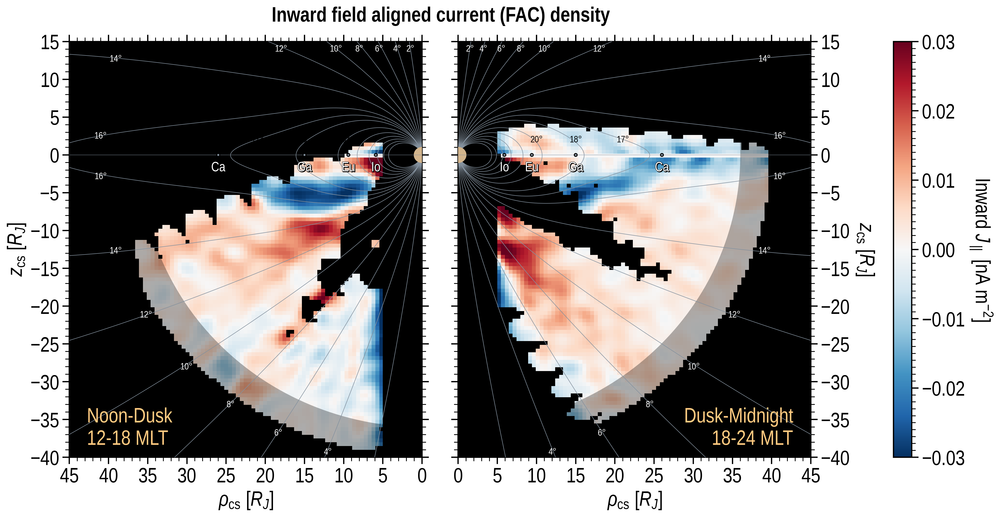

In [31]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.0,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (12-18)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Noon-Dusk\n12-18 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    -np.sign(Z_CS_1218)*J_para_1218,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1218.min(), RHO_CS_1218.max(),
        Z_CS_1218.min(),   Z_CS_1218.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Dusk-Midnight\n18-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    -np.sign(Z_CS_1824)*J_para_1824,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1824.min(), RHO_CS_1824.max(),
        Z_CS_1824.min(),   Z_CS_1824.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.linspace(-0.03, 0.03, 7))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(10))
pp.ax.set_ylabel(r'Inward $J_\parallel$ [nA m$^{-2}$]',
                 verticalalignment='bottom',
                 rotation=270)

fig.suptitle('Inward field aligned current (FAC) density', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

# Dawn/Dusk Side by Side

Text(0.5, 1.01, 'Inward field aligned current (FAC) density')

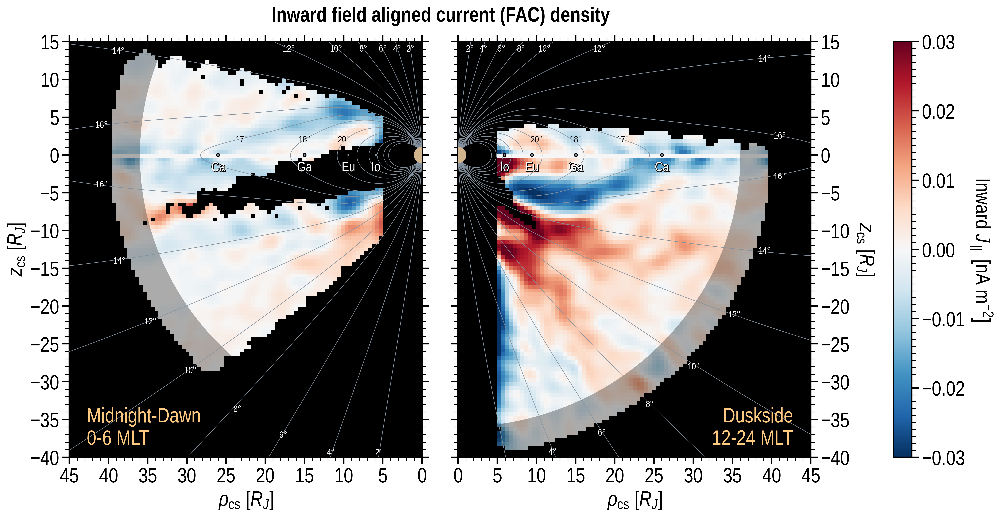

In [32]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.0,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    -np.sign(Z_CS_0060)*J_para_0060,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_0060.min(), RHO_CS_0060.max(),
        Z_CS_0060.min(),   Z_CS_0060.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    -np.sign(Z_CS_1224)*J_para_1224,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1224.min(), RHO_CS_1224.max(),
        Z_CS_1224.min(),   Z_CS_1224.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.linspace(-0.03, 0.03, 7))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(10))
pp.ax.set_ylabel(r'Inward $J_\parallel$ [nA m$^{-2}$]',
                 verticalalignment='bottom',
                 rotation=270)

fig.suptitle('Inward field aligned current (FAC) density', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

Text(0.5, 1.01, 'Inward field aligned current (FAC) density')

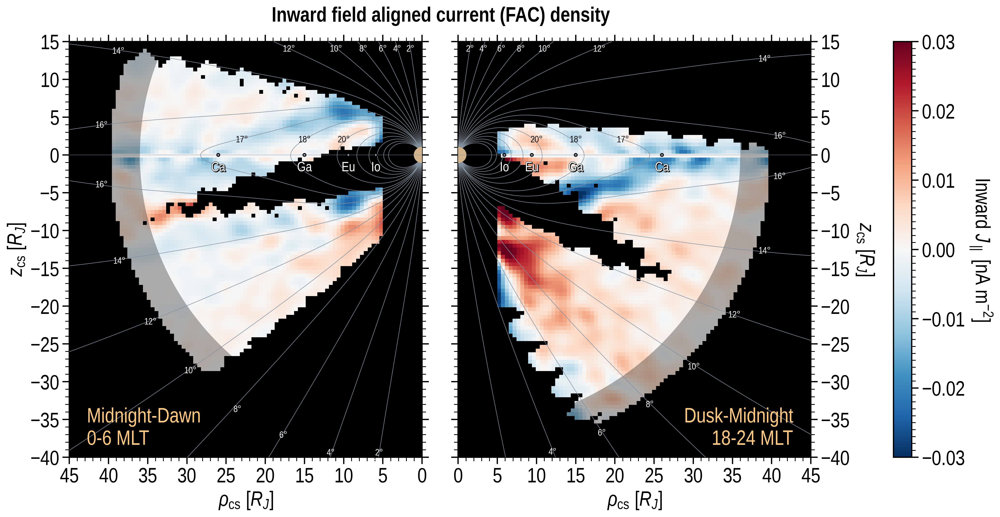

In [33]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.0,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    -np.sign(Z_CS_0060)*J_para_0060,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_0060.min(), RHO_CS_0060.max(),
        Z_CS_0060.min(),   Z_CS_0060.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Dusk-Midnight\n18-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vlim = 0.03
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    -np.sign(Z_CS_1824)*J_para_1824,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1824.min(), RHO_CS_1824.max(),
        Z_CS_1824.min(),   Z_CS_1824.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.linspace(-0.03, 0.03, 7))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(10))
pp.ax.set_ylabel(r'Inward $J_\parallel$ [nA m$^{-2}$]',
                 verticalalignment='bottom',
                 rotation=270)

fig.suptitle('Inward field aligned current (FAC) density', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

Text(0.5, 1.01, 'Radial field component residuals')

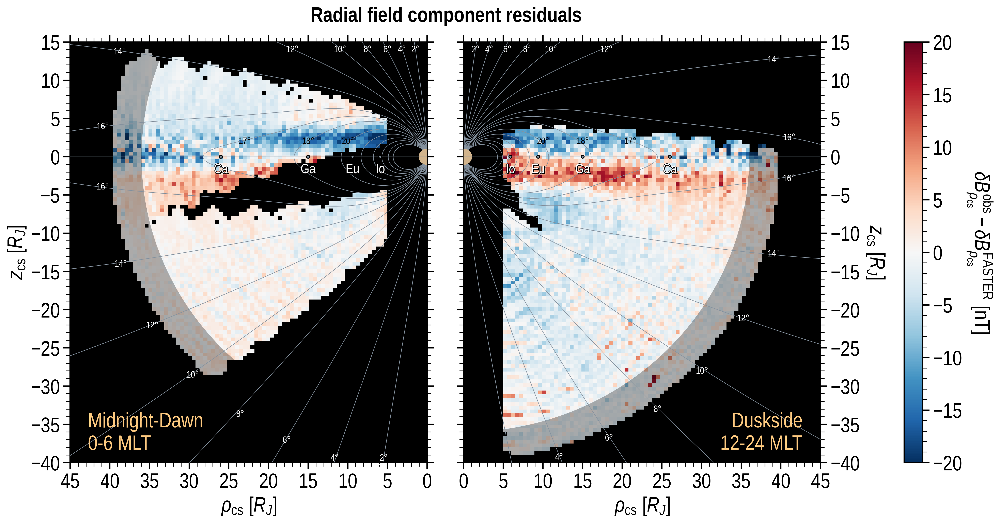

In [34]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.0,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vlim = 20.0
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    dBrho_cs_res_g_0060,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_0060.min(), RHO_CS_0060.max(),
        Z_CS_0060.min(),   Z_CS_0060.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vlim = 20.0
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    dBrho_cs_res_g_1224,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1224.min(), RHO_CS_1224.max(),
        Z_CS_1224.min(),   Z_CS_1224.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.arange(-20, 20+1, 5))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\delta B_{\rho_{\rm cs}}^{\rm obs}-\delta B_{\rho_{\rm cs}}^{\rm FASTER}$ [nT]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle('Radial field component residuals', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

Text(0.5, 1.01, 'Azimuthal field component residuals')

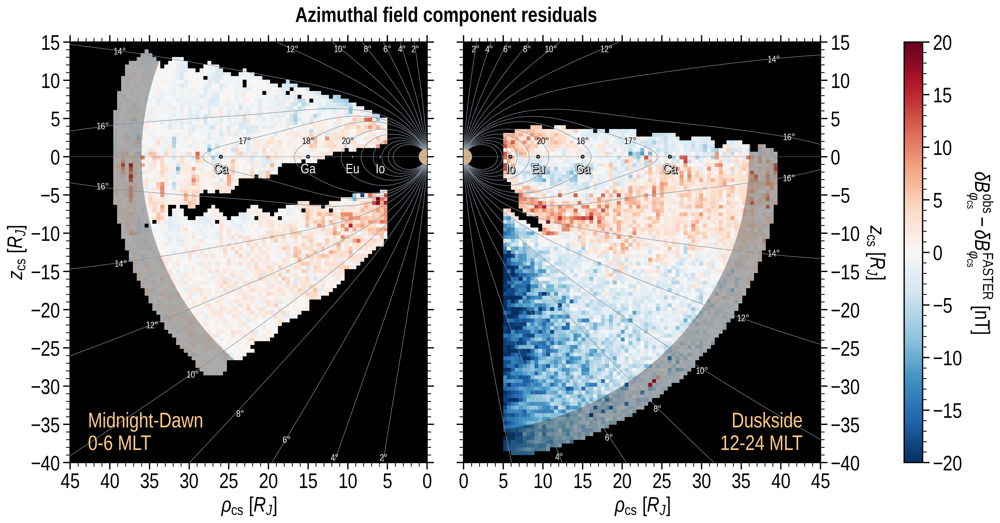

In [35]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.0,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vlim = 20.0
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    dBphi_cs_res_g_0060,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_0060.min(), RHO_CS_0060.max(),
        Z_CS_0060.min(),   Z_CS_0060.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vlim = 20.0
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    dBphi_cs_res_g_1224,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1224.min(), RHO_CS_1224.max(),
        Z_CS_1224.min(),   Z_CS_1224.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.arange(-20, 20+1, 5))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\delta B_{\varphi_{\rm cs}}^{\rm obs}-\delta B_{\varphi_{\rm cs}}^{\rm FASTER}$ [nT]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle('Azimuthal field component residuals', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

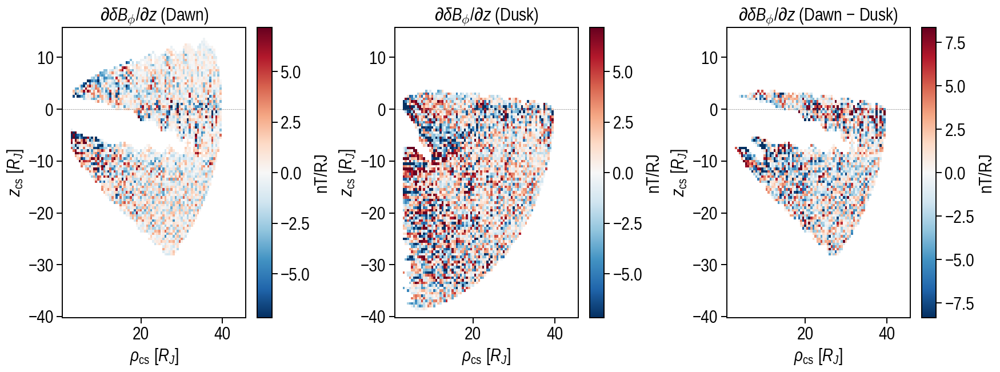

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# ∂δBφ/∂z を計算
ddBphi_dz_dawn = np.gradient(dBphi_cs_res_g_0060, grid_z_cs, axis=0)
ddBphi_dz_dusk = np.gradient(dBphi_cs_res_g_1224, grid_z_cs, axis=0)

# 差分
diff = ddBphi_dz_dawn - ddBphi_dz_dusk

vmax = np.nanpercentile(np.abs([ddBphi_dz_dawn, ddBphi_dz_dusk]), 95)
vmax_diff = np.nanpercentile(np.abs(diff), 95)

norm = mplcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
norm_diff = mplcolors.TwoSlopeNorm(vmin=-vmax_diff, vcenter=0, vmax=vmax_diff)

# Dawn
ax = axes[0]
cf = ax.pcolormesh(RHO_CS, Z_CS, ddBphi_dz_dawn,
                   cmap='RdBu_r', norm=norm, shading='auto')
ax.set_title(r'$\partial\delta B_\phi/\partial z$ (Dawn)')
plt.colorbar(cf, ax=ax, label='nT/RJ')

# Dusk
ax = axes[1]
cf = ax.pcolormesh(RHO_CS, Z_CS, ddBphi_dz_dusk,
                   cmap='RdBu_r', norm=norm, shading='auto')
ax.set_title(r'$\partial\delta B_\phi/\partial z$ (Dusk)')
plt.colorbar(cf, ax=ax, label='nT/RJ')

# 差分（Dawn - Dusk）
ax = axes[2]
cf = ax.pcolormesh(RHO_CS, Z_CS, diff,
                   cmap='RdBu_r', norm=norm_diff, shading='auto')
ax.set_title(r'$\partial\delta B_\phi/\partial z$ (Dawn $-$ Dusk)')
plt.colorbar(cf, ax=ax, label='nT/RJ')

for ax in axes:
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')
    ax.axhline(0, color='gray', lw=0.5, ls='--')

plt.tight_layout()
plt.show()

Text(0.5, 1.01, 'z field component residuals')

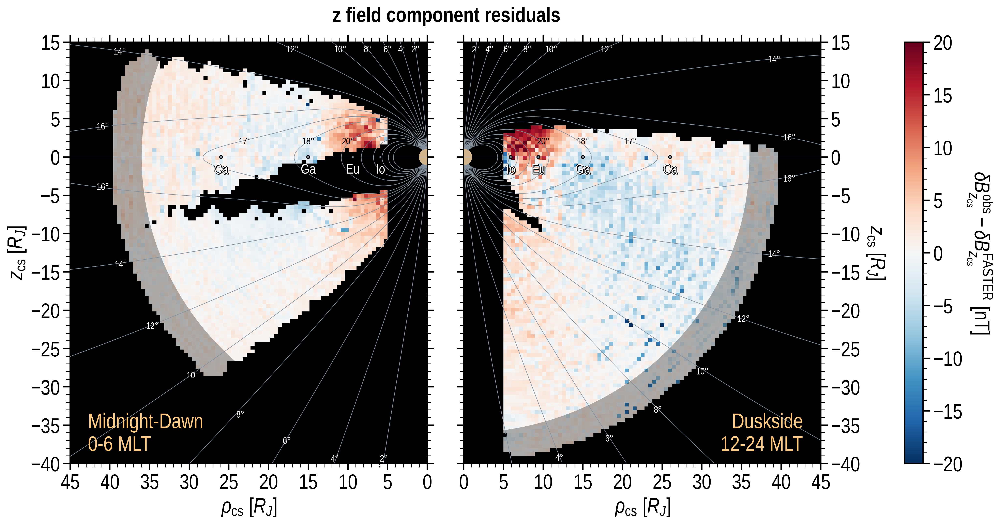

In [37]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor('k')
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-40.0, 15.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-40, 15+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
    radii = [5.9, 9.4, 15.0, 26.0]
    name = ['Io', 'Eu', 'Ga', 'Ca']
    labelz = [-1.5, -1.5, -1.5, -1.5]
    for i in range(len(radii)):
        ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                zorder=8, fill=True, clip_on=True))
        F.textbox(ax_idx=ax,
                  x=radii[i], y=labelz[i],
                  text=name[i],
                  textedge=True,
                  fontsize=F.fontsize*0.65,
                  facealpha=0.0,
                  edgecolor='none',
                  horizontalalignment='center',
                  zorder=8)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    for r_in, r_out in [(36, 41)]:
        # 上半分（z_cs > 0, つまり角度0-180度）
        wedge_top = Wedge(
            center=(0, 0),      # 木星の位置
            r=r_out,            # 外半径
            theta1=0,           # 開始角度
            theta2=360,         # 終了角度
            width=r_out - r_in,  # 幅 = 4 RJ
            facecolor='k',
            edgecolor=None,
            alpha=0.30,
            linewidth=3.0,
            transform=ax.transData,
            zorder=4.9,
        )
        ax.add_patch(wedge_top)
        ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vlim = 20.0
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    dBz_cs_res_g_0060,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_0060.min(), RHO_CS_0060.max(),
        Z_CS_0060.min(),   Z_CS_0060.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)


# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N2.shape[0]):
    rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S2.shape[0]):
    rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S2[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-82, -73.5, -64.5, -55, -44, -32.5, -20, -5.5, 5.5, 19.5]
label_list = [2, 4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5, 7.5, 11, 17]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [5.5]
label_list = [2]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], -40.0, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='bottom',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 23]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vlim = 20.0
clim = (-vlim, vlim)

norm = mplcolors.TwoSlopeNorm(vmin=clim[0], vcenter=0, vmax=clim[1])
cf = ax.imshow(
    dBz_cs_res_g_1224,
    cmap='RdBu_r',
    norm=norm,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS_1224.min(), RHO_CS_1224.max(),
        Z_CS_1224.min(),   Z_CS_1224.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)

# ===========================================================
# Magnetic field line
# ===========================================================
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.55, color=UC.gray, zorder=5)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
r_arc = 41.1  # RJ
rho_min, rho_max = 0.0, 45.0
z_min, z_max = -40.0, 15.0

lat_deg_list = [-73, -63.5, -53.5, -43, -31, -18, -4, 3.5, 18]
label_list = [4, 6, 8, 10, 12, 14, 16, 16, 14]
for i in range(len(lat_deg_list)):
    lat_deg = lat_deg_list[i]
    lat_rad = np.deg2rad(lat_deg)
    rho_i = r_arc * np.cos(lat_rad)
    z_i = r_arc * np.sin(lat_rad)

    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

    ax.text(
        rho_i, z_i, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [1.5, 3.2, 5.5, 8.0, 11, 18]
label_list = [2, 4, 6, 8, 10, 12]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 14, label,
        fontsize=F.fontsize*0.45,
        color='white',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )
lat_x_list = [10, 15, 21]
label_list = [20, 18, 17]
for i in range(len(lat_x_list)):
    # ラベル文字列（例: "+10°", "-8°", "0°"）
    label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
    ax.text(
        lat_x_list[i], 2, label,
        fontsize=F.fontsize*0.45,
        color='k',
        ha='center', va='center',
        rotation=0,
        zorder=10,
    )


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.arange(-20, 20+1, 5))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\delta B_{z_{\rm cs}}^{\rm obs}-\delta B_{z_{\rm cs}}^{\rm FASTER}$ [nT]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle('z field component residuals', y=1.01,
             fontsize=F.fontsize, fontweight="bold")